This dataset contains information on new born babies and their parents.  It contains mostly continuous variables (although some have only a few values e.g. number of cigarettes smoked per day) and is most useful for correlation and regression.  The birthweights of the babies who mothers smoked have been adjusted slightly to exaggerate the differences between mothers who smoked and didn’t smoke so students can see the difference more clearly in a scatterplot with gestational age and scatter colour coded by smoking status.   

| Name | Variable | Data type |
| --- | --- | --- |
| ID | Baby number	|
| length |	Length of baby (cm) |	Scale
| Birthweight |	Weight of baby (kg) |	Scale
| headcirumference |	Head Circumference |	Scale
| Gestation |	Gestation (weeks) |	Scale
| smoker |	Mother smokes 1 = smoker 0 = non-smoker |	 Binary
| motherage |	Maternal age |	Scale
| mnocig |	Number of cigarettes smoked per day by mother |	Scale
| mheight |	Mothers height (cm) |	 Scale
| mppwt |	Mothers pre-pregnancy weight (kg) |	 Scale
| fage |	Father's age |	 Scale
|fedyrs |	Father’s years in education |	Scale
| fnocig |	Number of cigarettes smoked per day by father |	Scale
| fheight |	Father's height (kg) |	 Scale
| lowbwt |	Low birth weight, 0 = No and 1 = yes |	 Binary
| mage35 |	Mother over 35, 0 = No and 1 = yes |	Binary

In [50]:
import pandas as pd
import seaborn as sns
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures


In [41]:
df = pd.read_csv('birthweight.csv')
df.head()

,ID,Length,Birthweight,Headcirc,Gestation,smoker,mage,mnocig,mheight,mppwt,fage,fedyrs,fnocig,fheight,lowbwt,mage35
0,1360,56,4.55,34,44,0,20,0,162,57,23,10,35,179,0,0
1,1016,53,4.32,36,40,0,19,0,171,62,19,12,0,183,0,0
2,462,58,4.10,39,41,0,35,0,172,58,31,16,25,185,0,1
3,1187,53,4.07,38,44,0,20,0,174,68,26,14,25,189,0,0
4,553,54,3.94,37,42,0,24,0,175,66,30,12,0,184,0,0


In [51]:
df.isnull().sum()

ID             0
Length         0
Birthweight    0
Headcirc       0
Gestation      0
smoker         0
mage           0
mnocig         0
mheight        0
mppwt          0
fage           0
fedyrs         0
fnocig         0
fheight        0
lowbwt         0
mage35         0
dtype: int64

In [52]:
df.dtypes

ID               int64
Length           int64
Birthweight    float64
Headcirc         int64
Gestation        int64
smoker           int64
mage             int64
mnocig           int64
mheight          int64
mppwt            int64
fage             int64
fedyrs           int64
fnocig           int64
fheight          int64
lowbwt           int64
mage35           int64
dtype: object

1. Normal distribution
2. Linearity
3. Y values are independent of each other

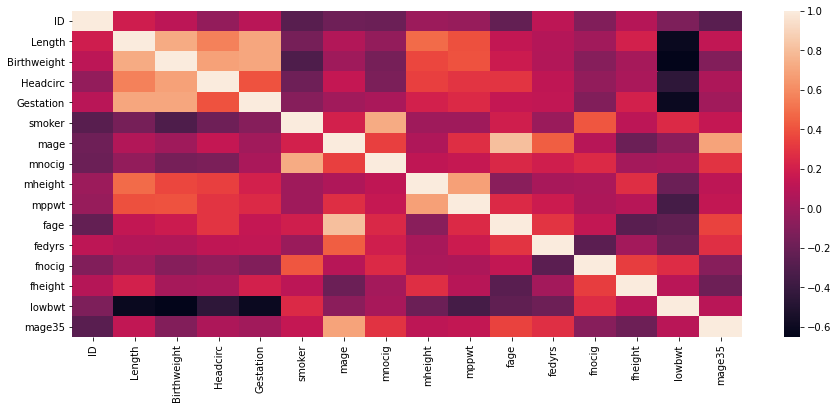

In [44]:
fig, ax = plt.subplots(1,1, figsize=(15, 6))
sns.heatmap(df.corr());

In [53]:
df[['Birthweight','Length']].corr()

,Birthweight,Length
Birthweight,1.000000,0.726833
Length,0.726833,1.000000


In [54]:
df[['Birthweight','Gestation']].corr()

,Birthweight,Gestation
Birthweight,1.000000,0.708303
Gestation,0.708303,1.000000


In [55]:
df[['Birthweight','Headcirc']].corr()

,Birthweight,Headcirc
Birthweight,1.000000,0.684616
Headcirc,0.684616,1.000000


<AxesSubplot:xlabel='Length', ylabel='Birthweight'>

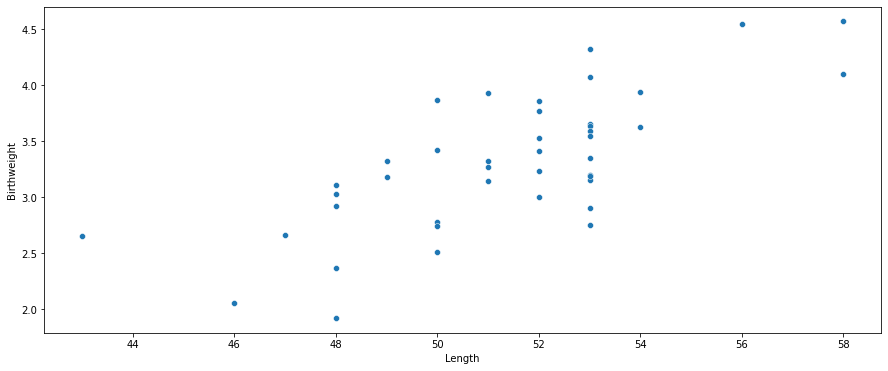

In [56]:
fig, ax = plt.subplots(1,1, figsize=(15, 6))
sns.scatterplot(data=df, x="Length", y="Birthweight")

<ipython-input-62-87fb163e90ed>:4: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  fig, ax = plt.subplots(1,1, figsize=(15, 6))


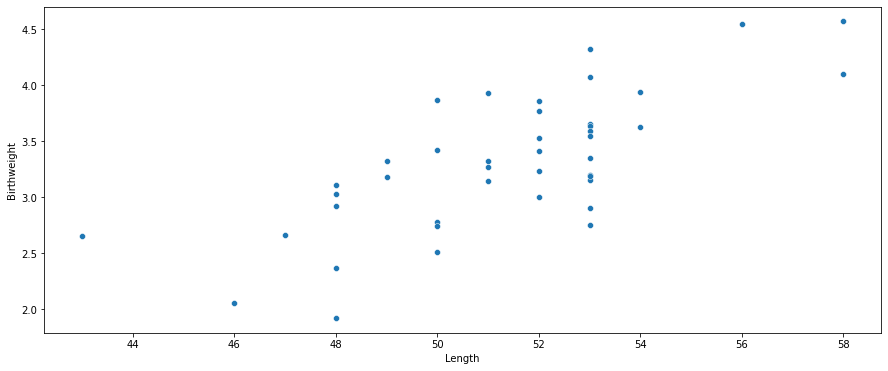

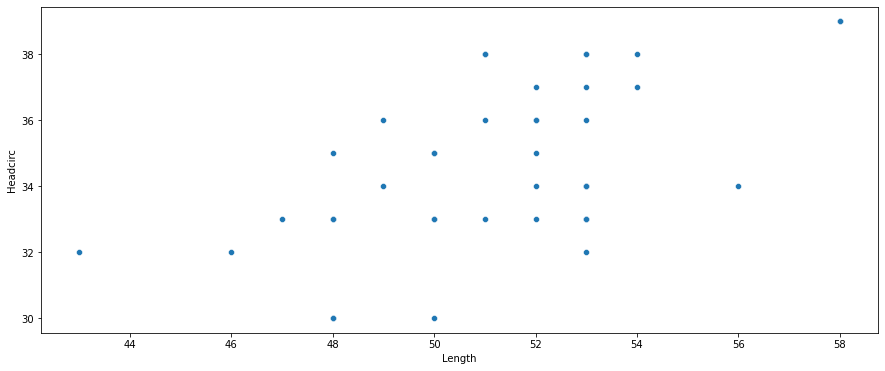

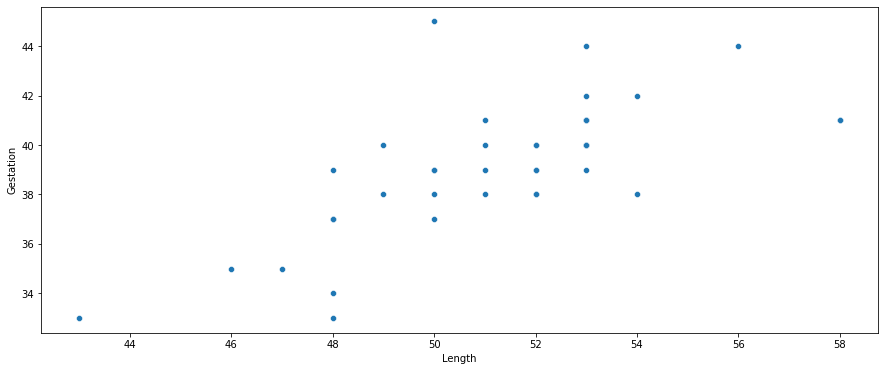

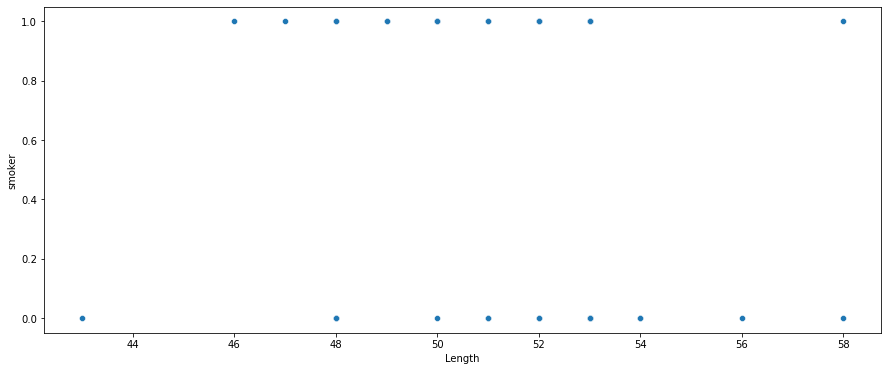

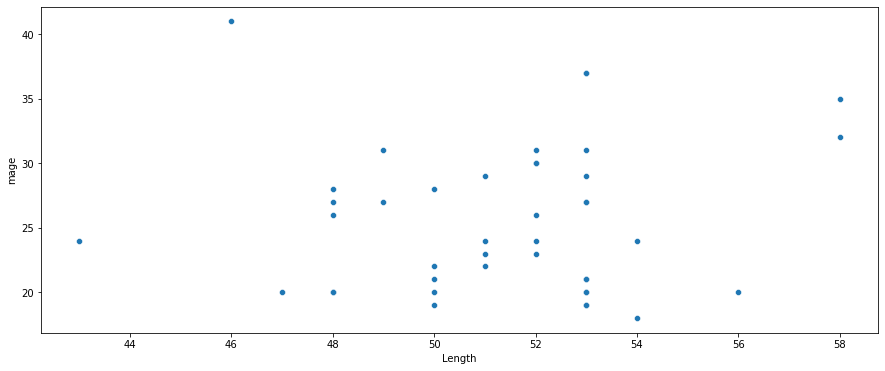

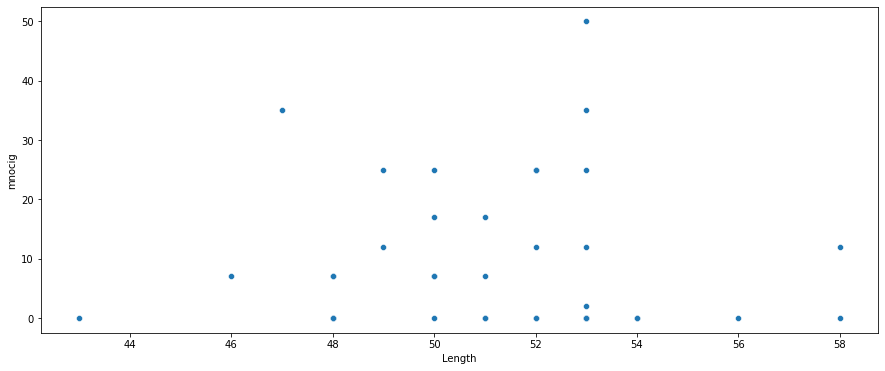

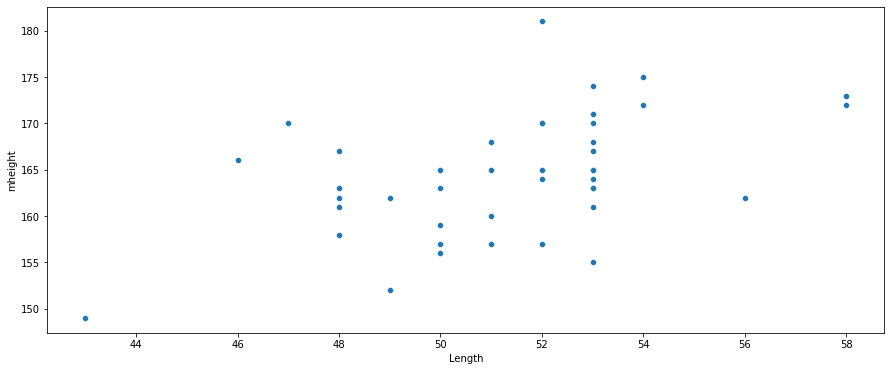

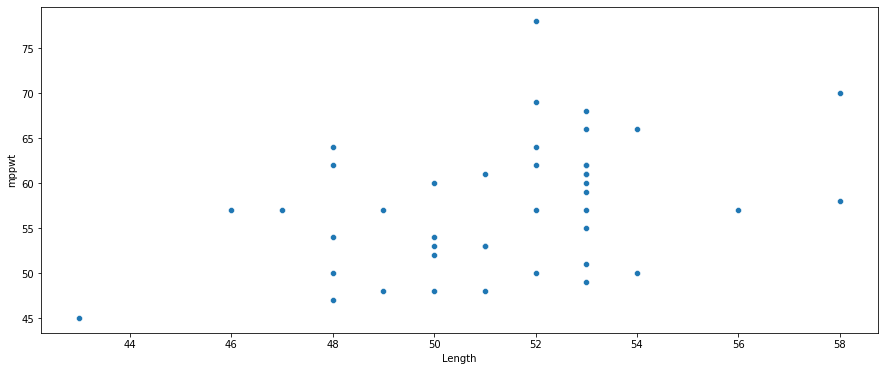

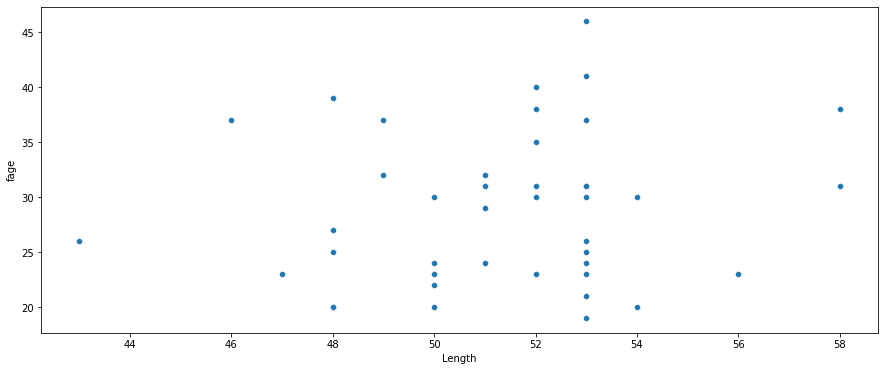

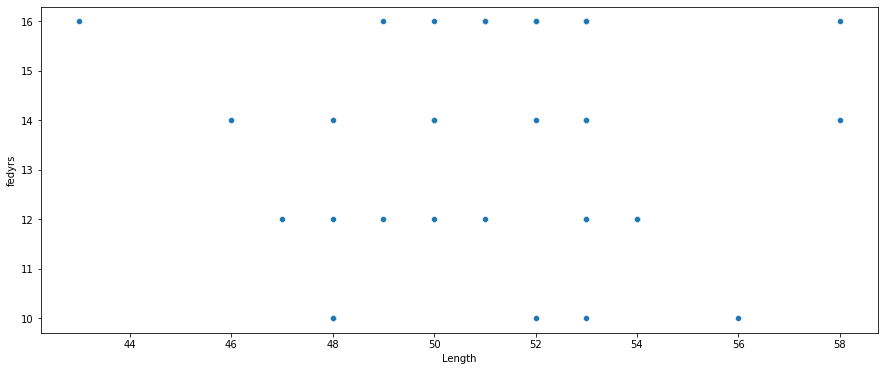

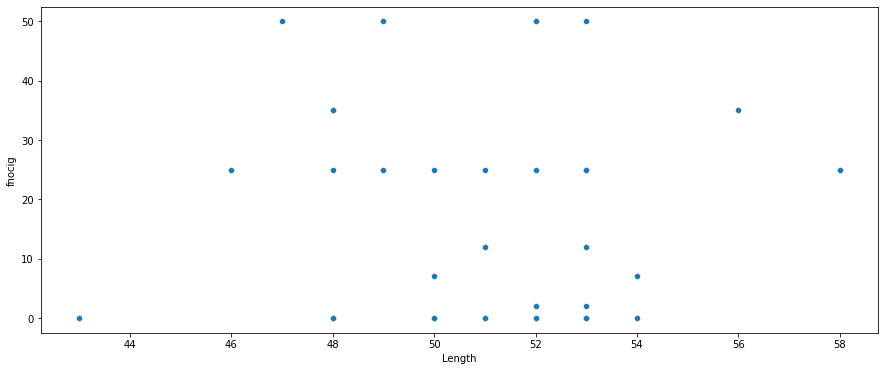

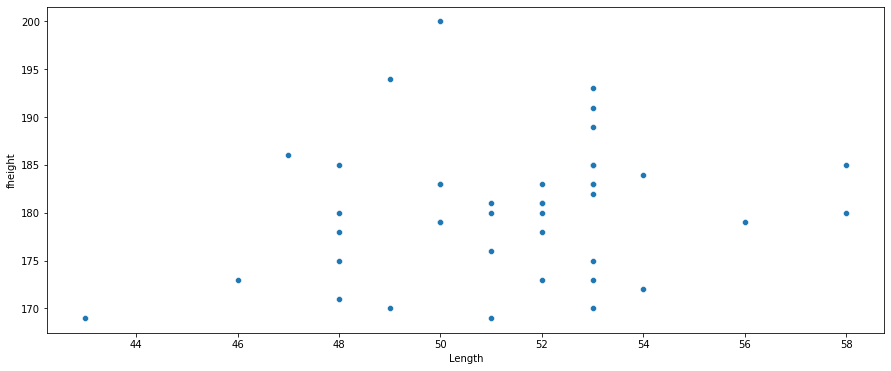

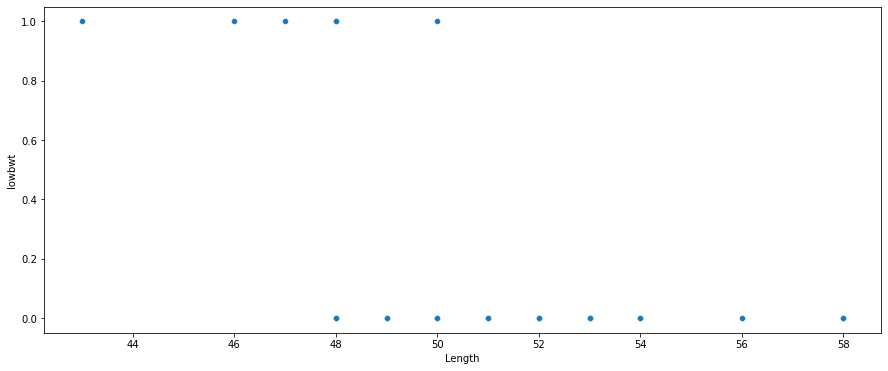

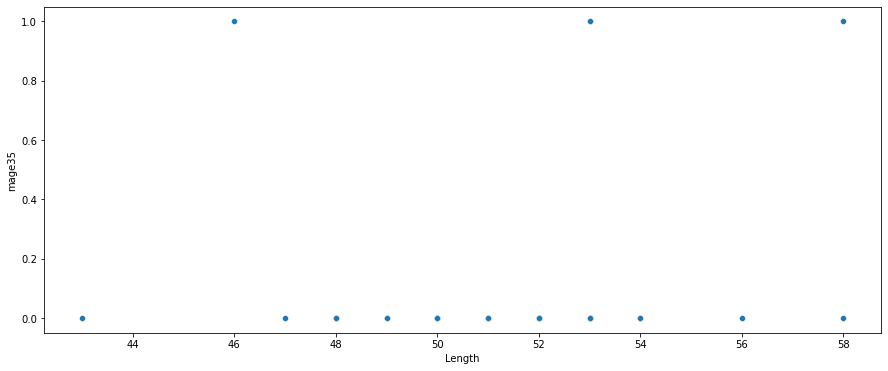

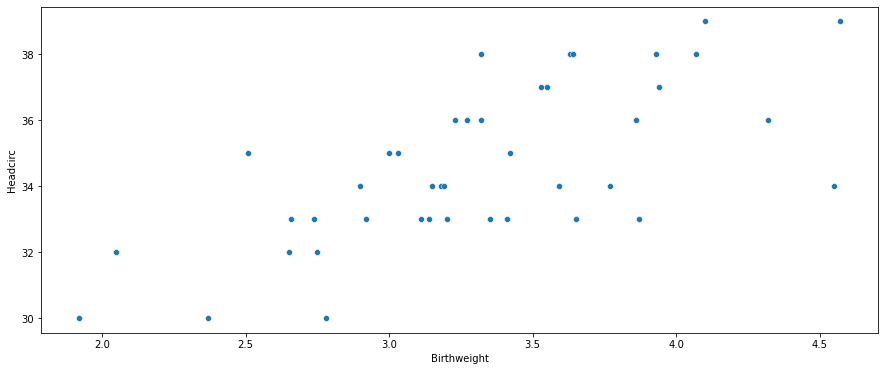

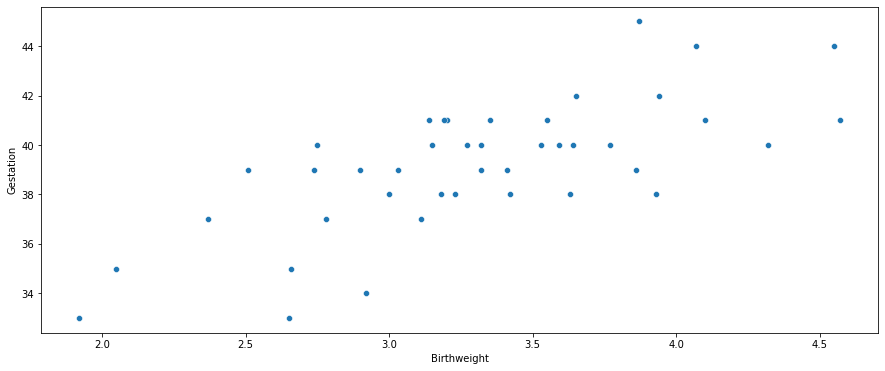

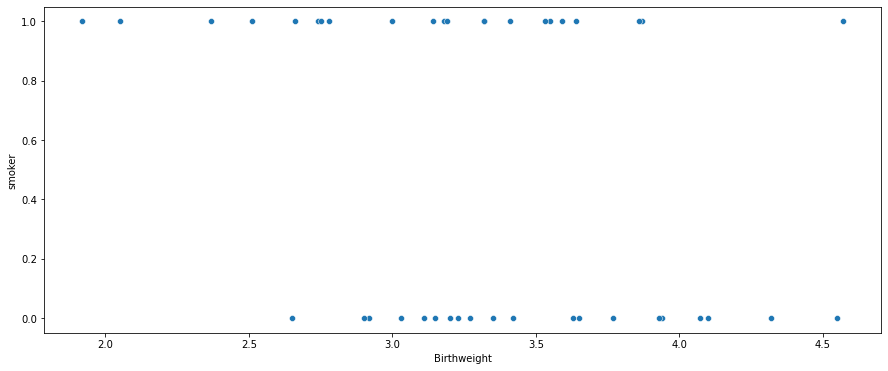

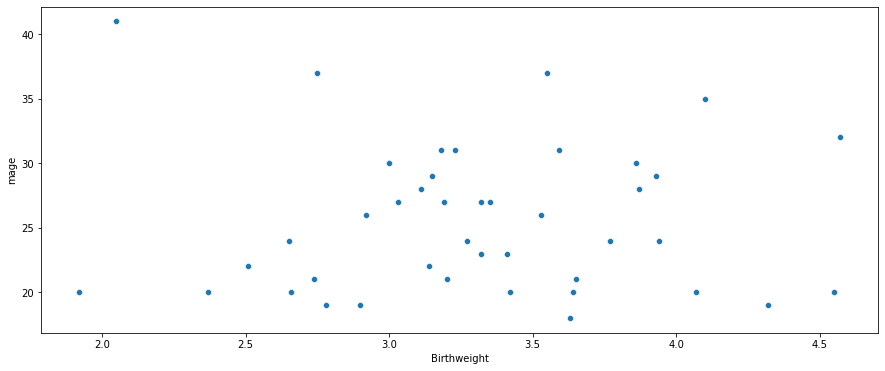

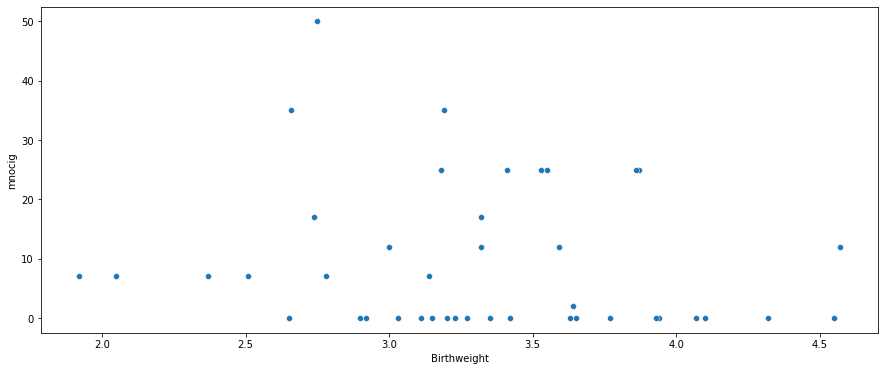

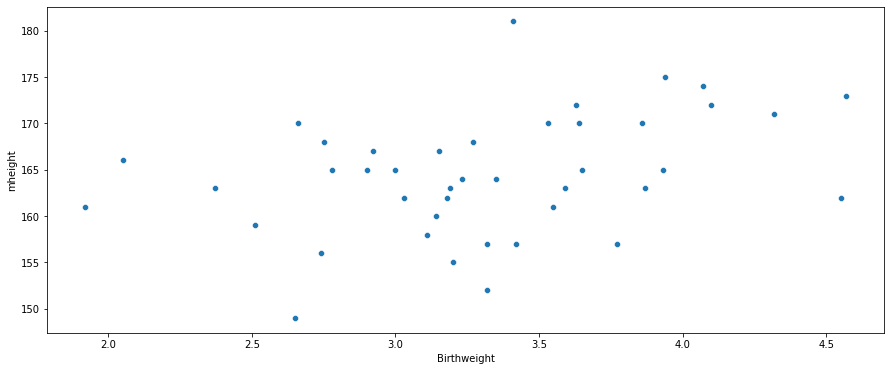

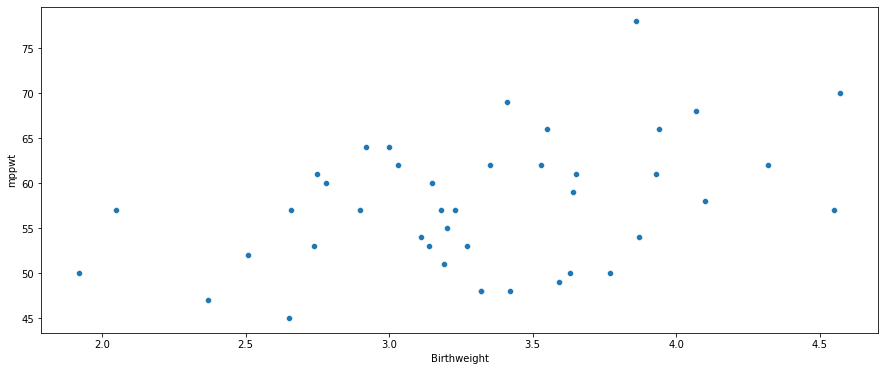

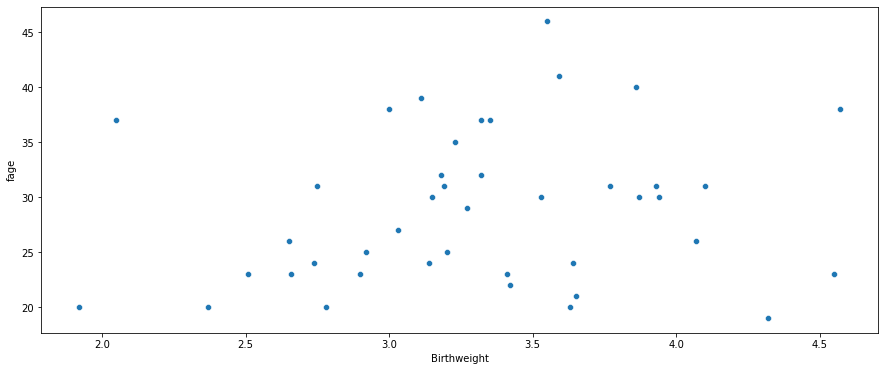

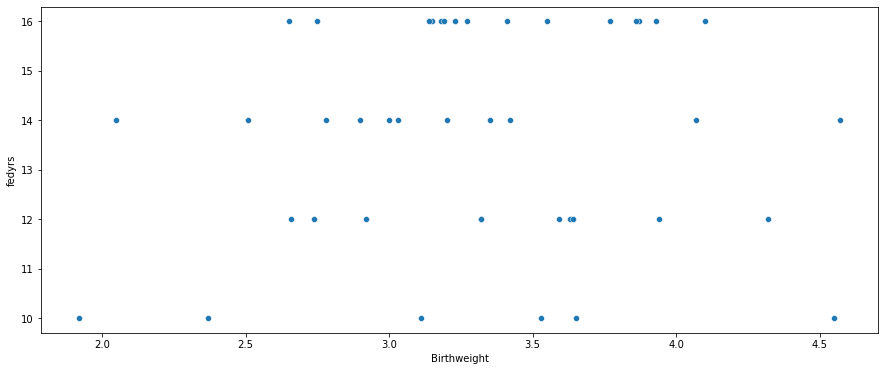

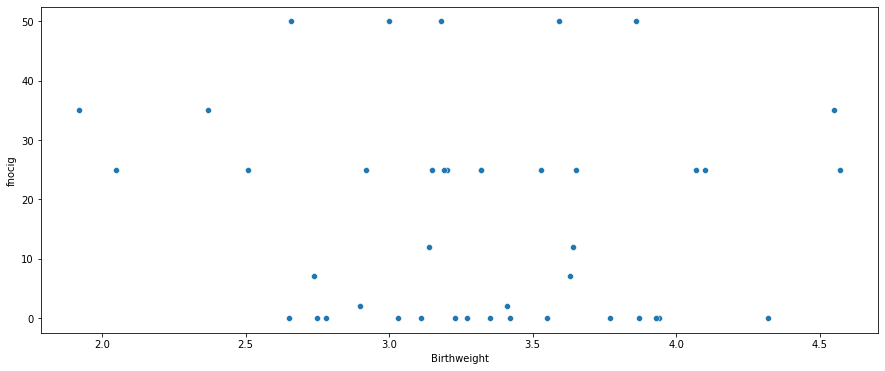

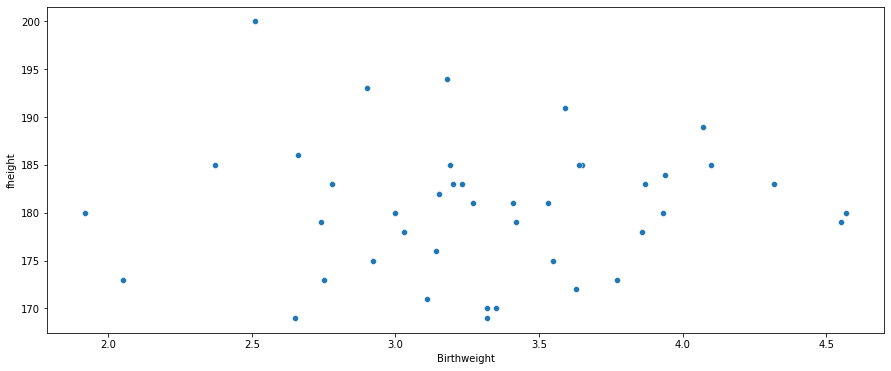

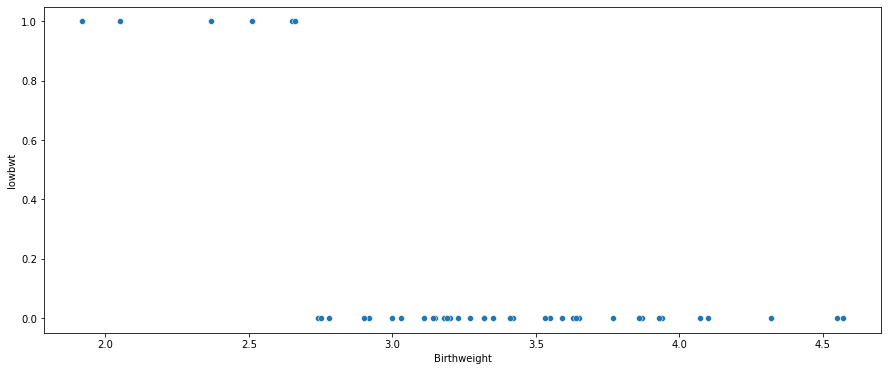

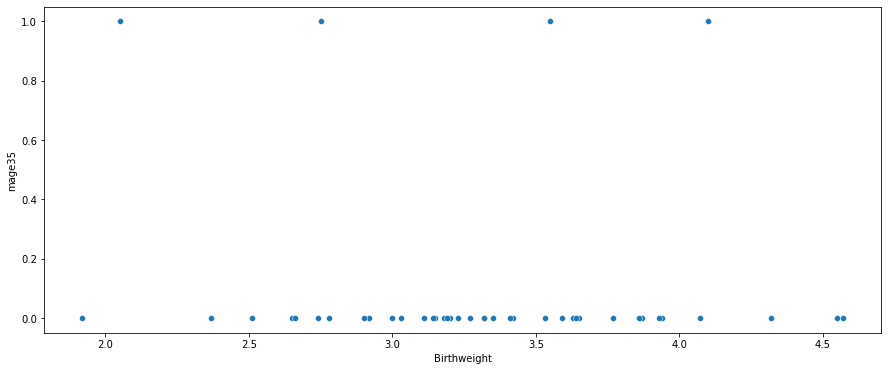

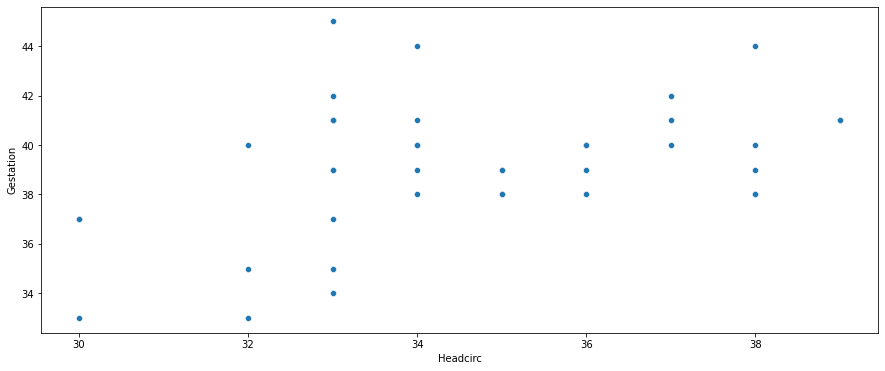

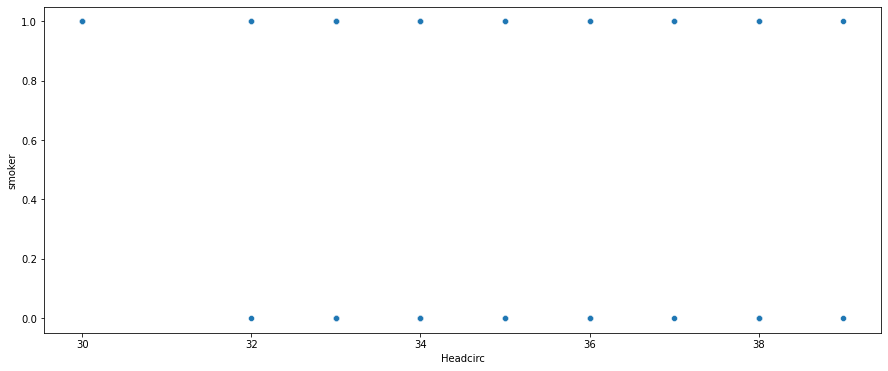

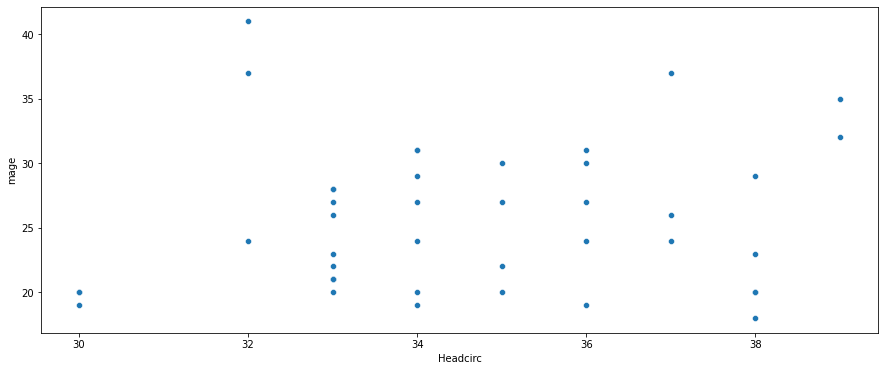

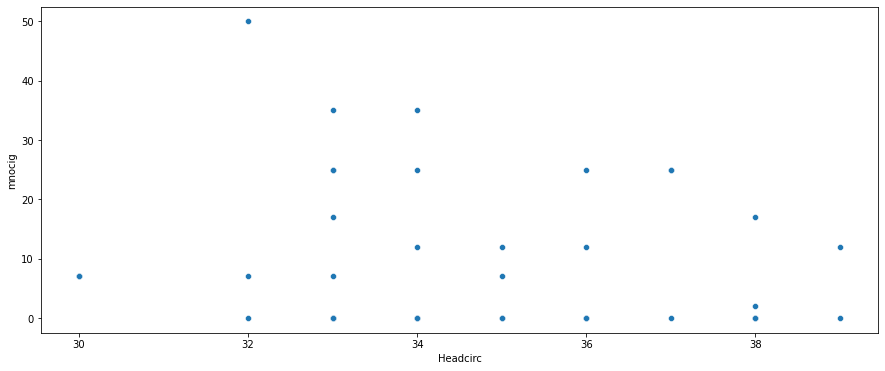

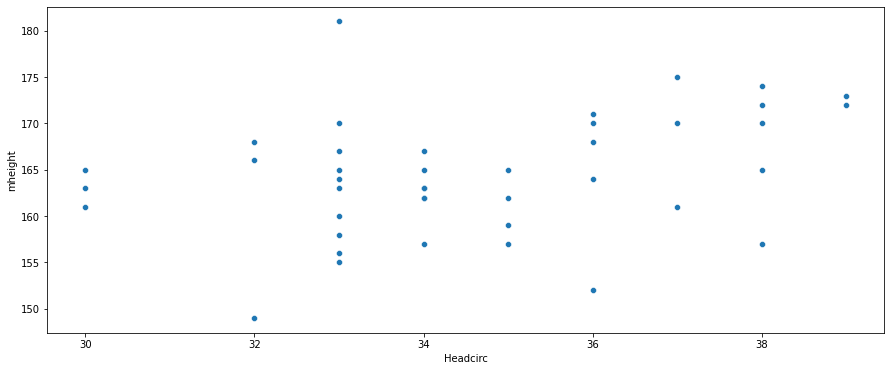

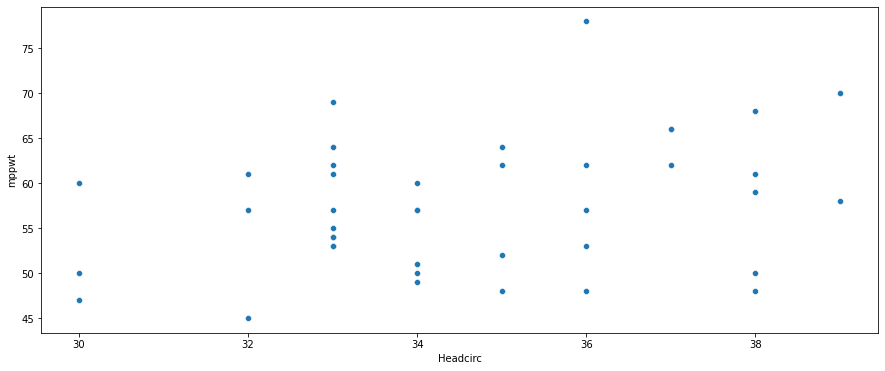

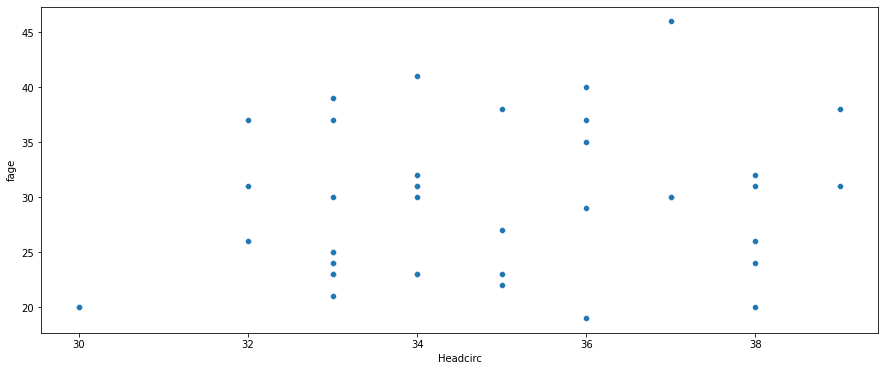

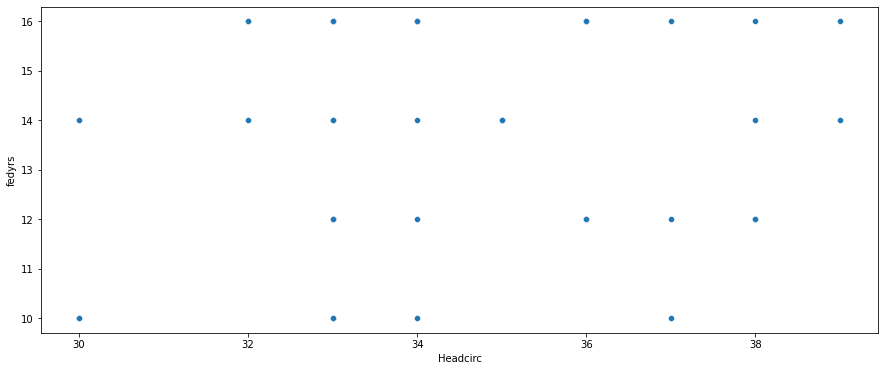

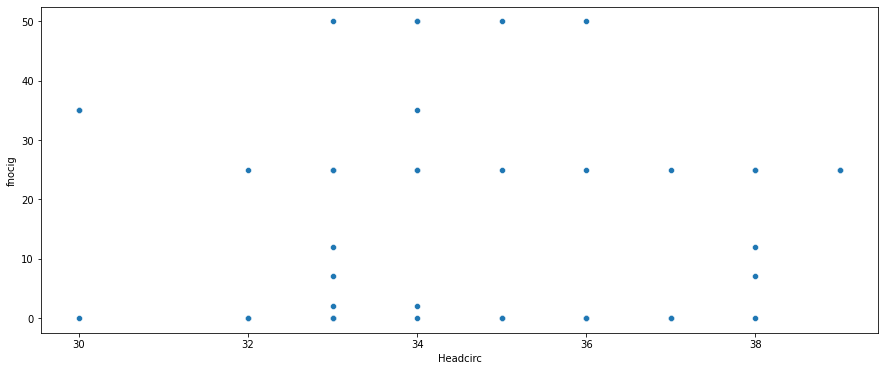

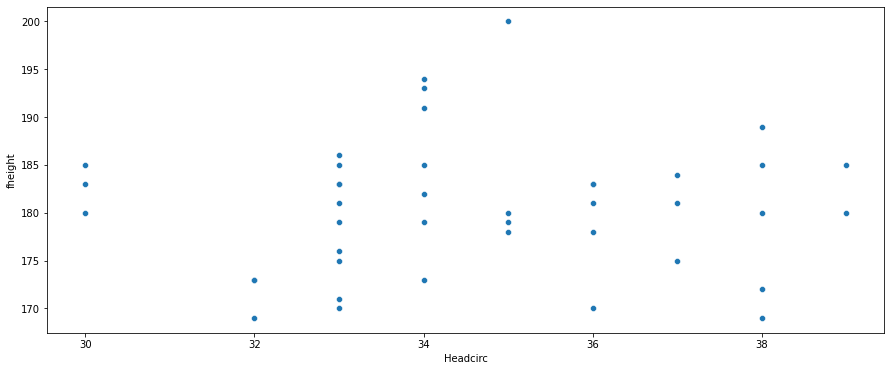

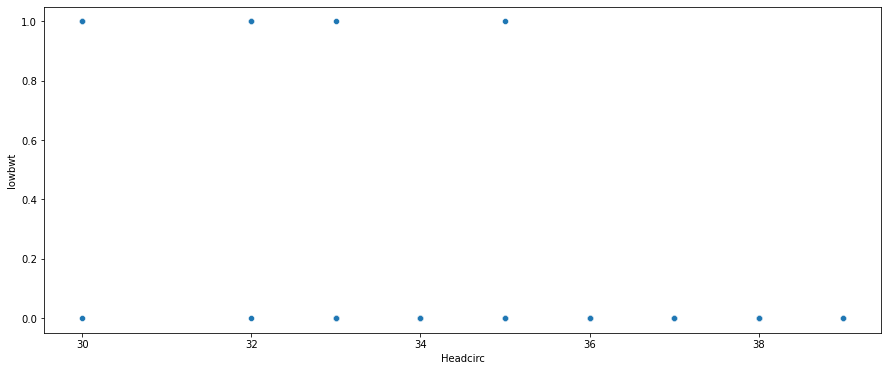

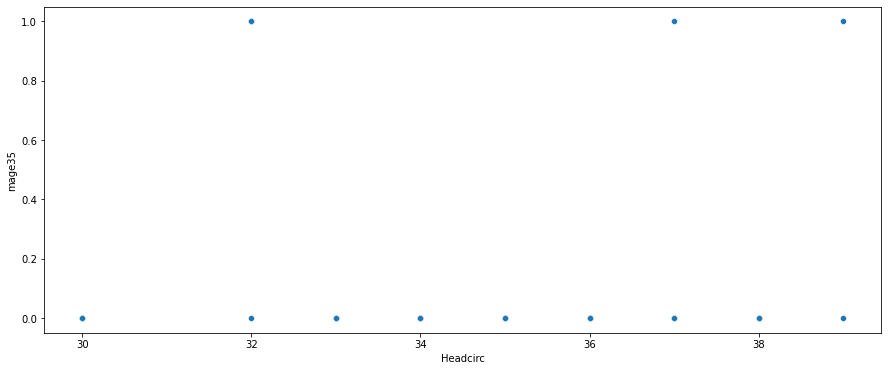

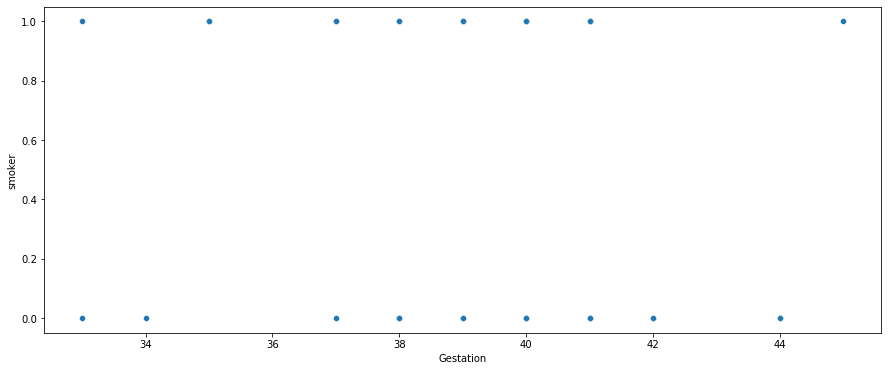

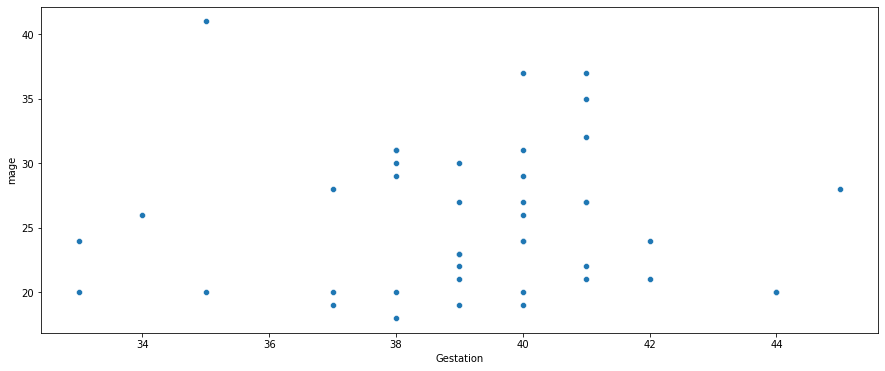

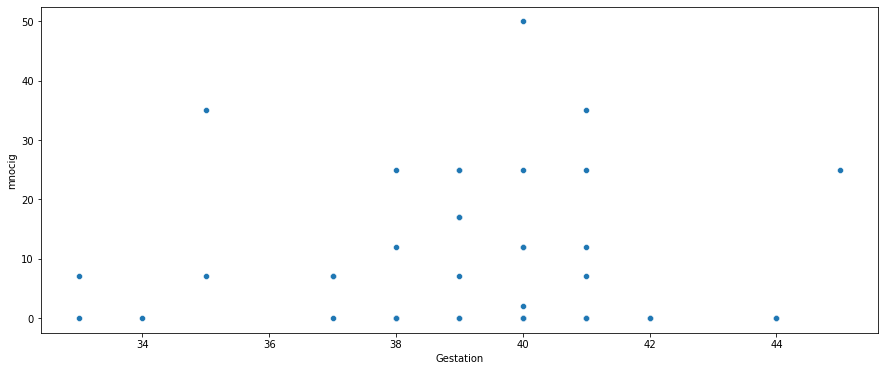

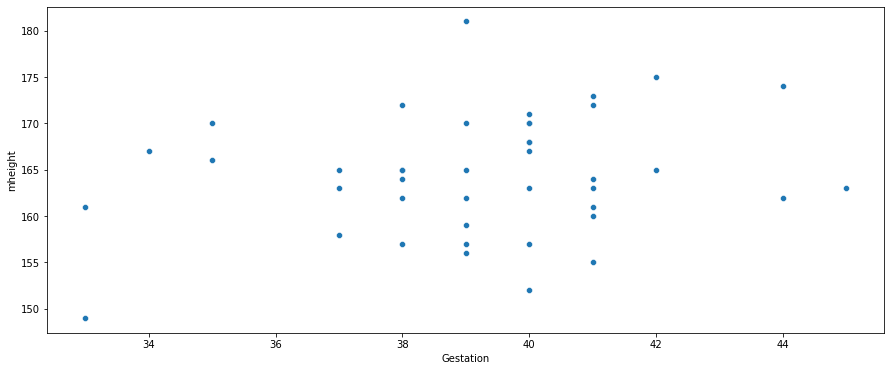

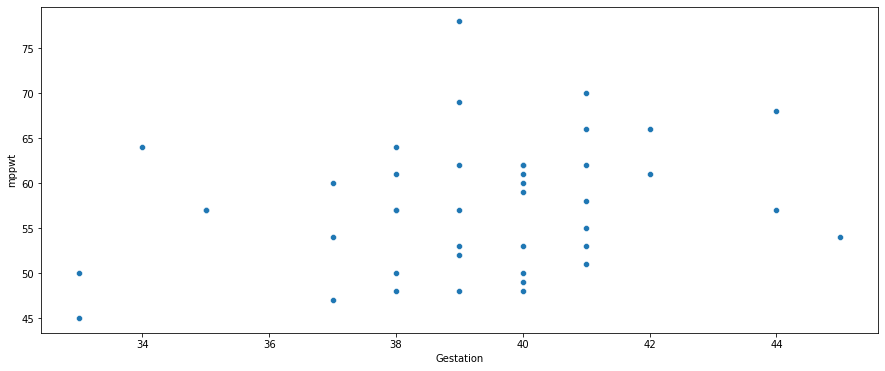

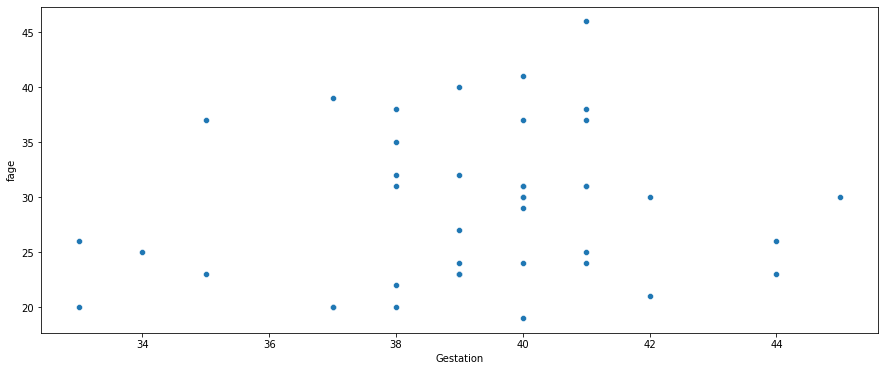

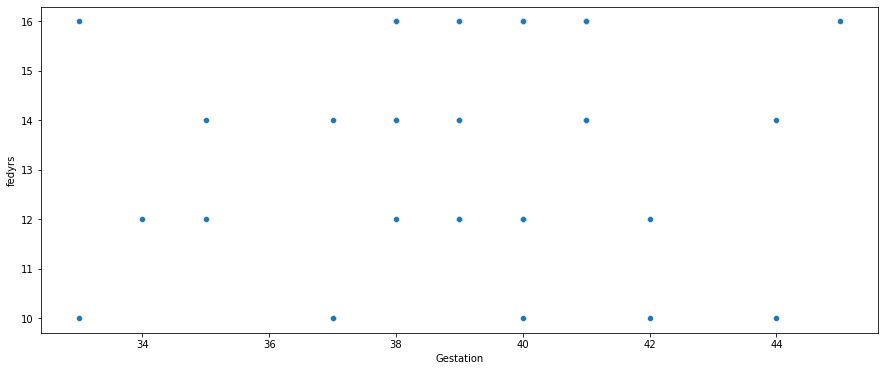

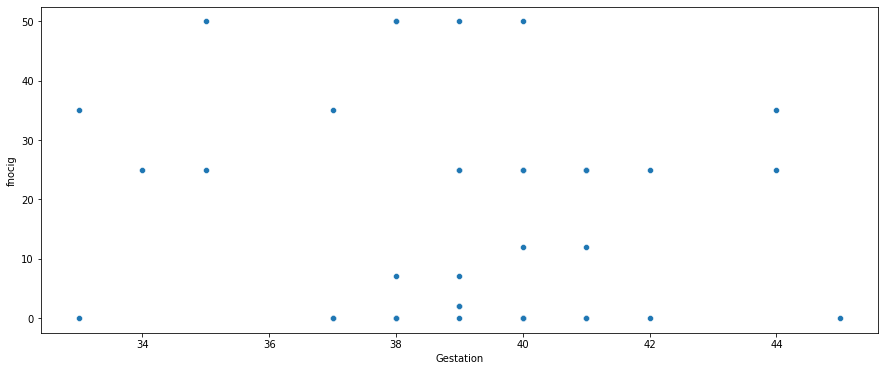

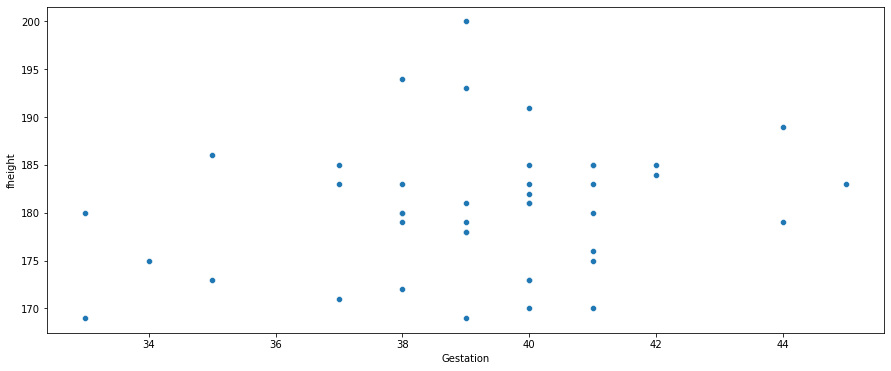

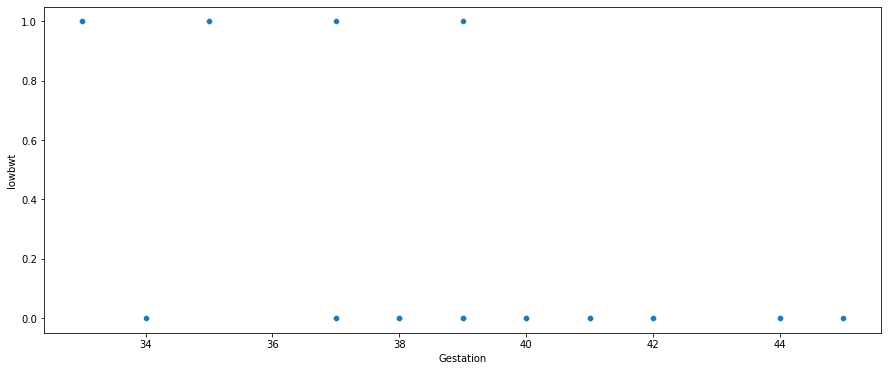

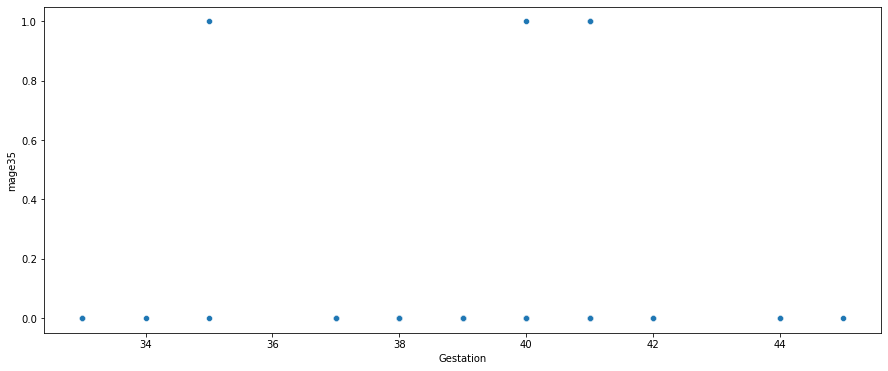

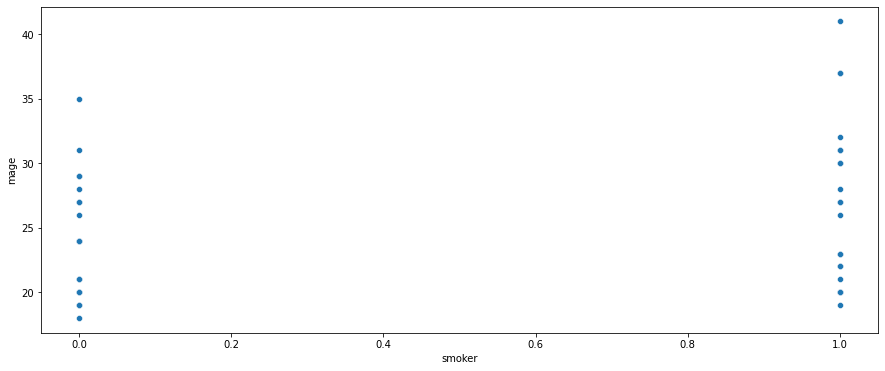

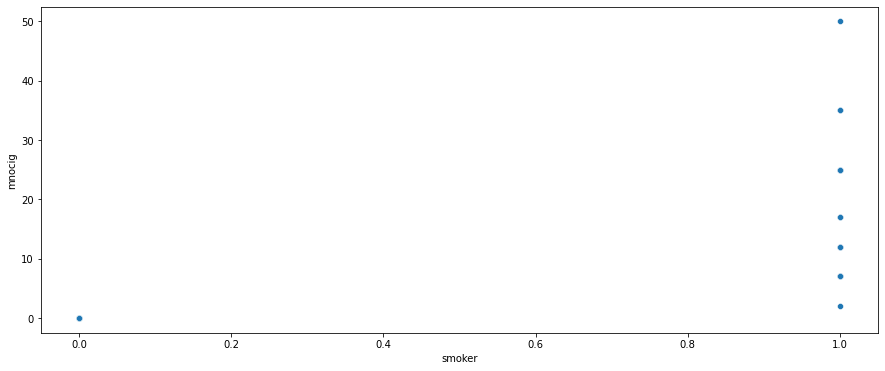

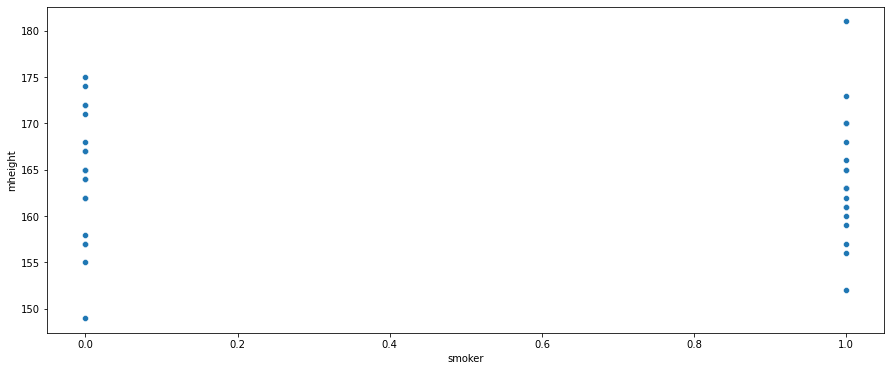

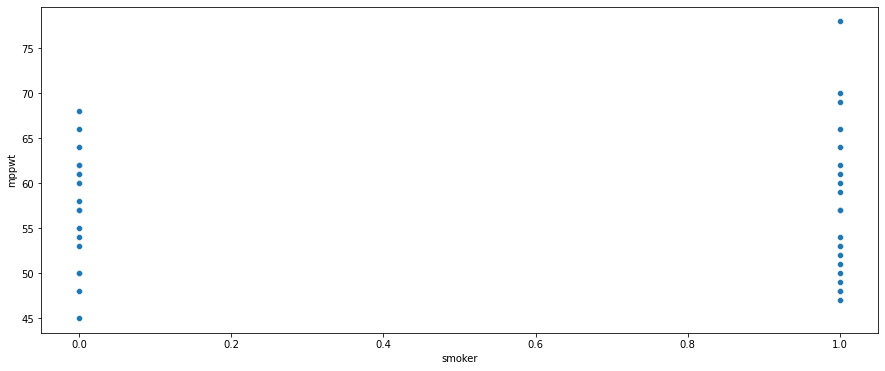

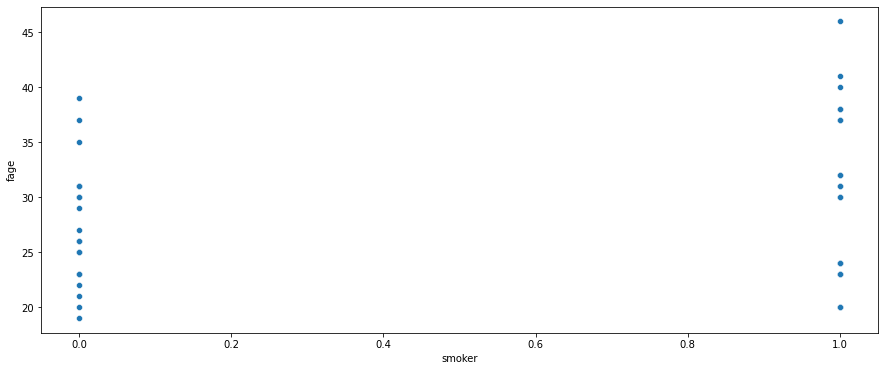

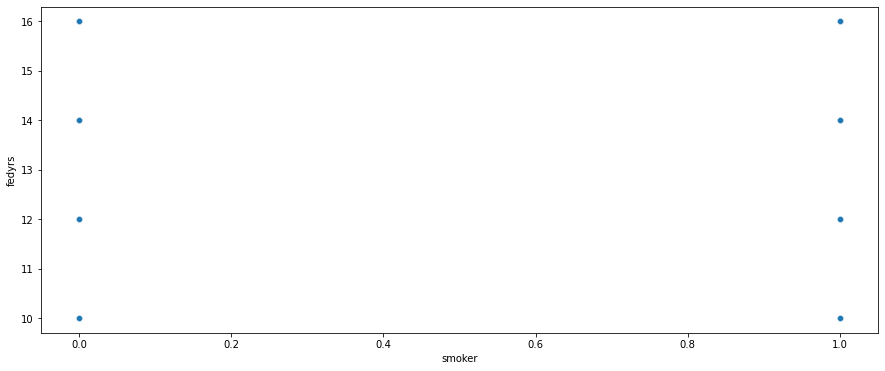

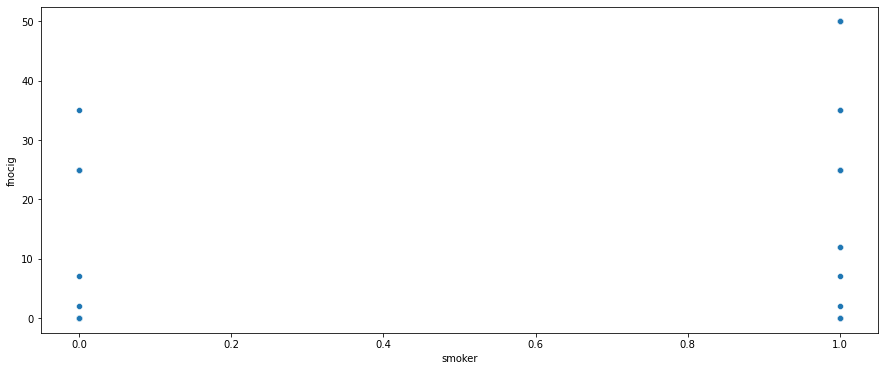

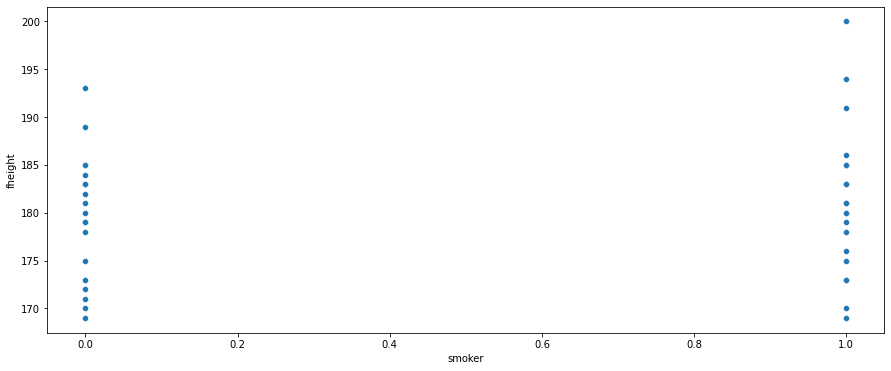

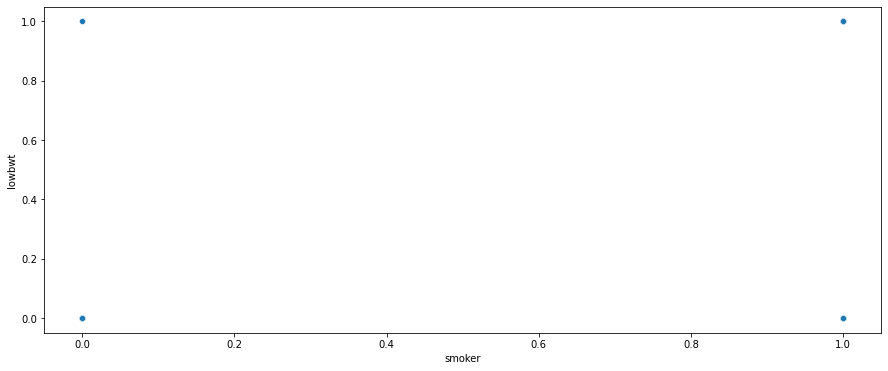

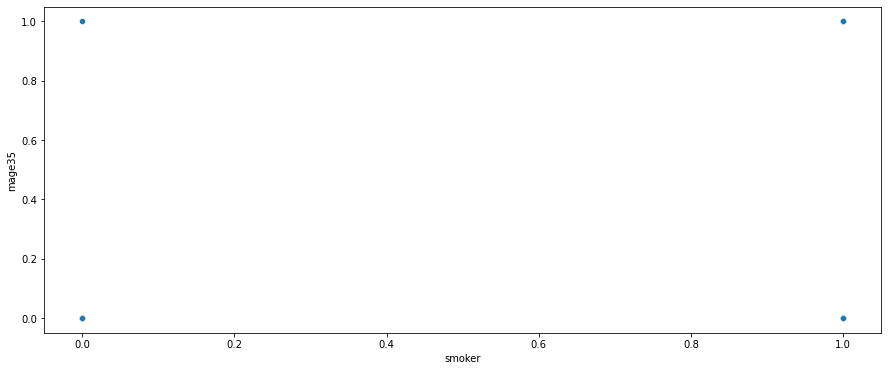

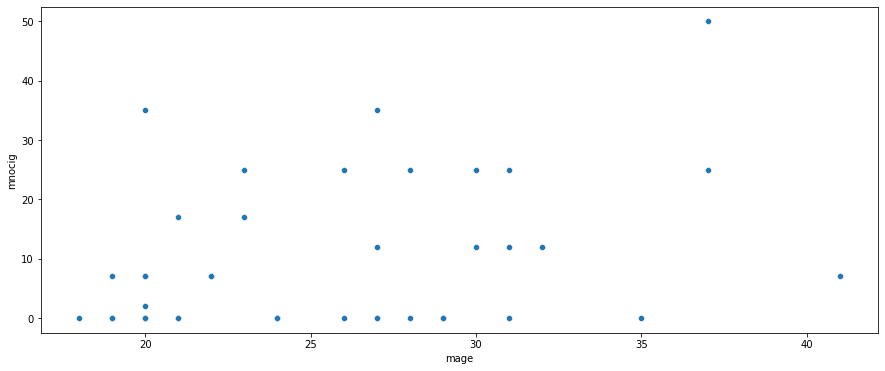

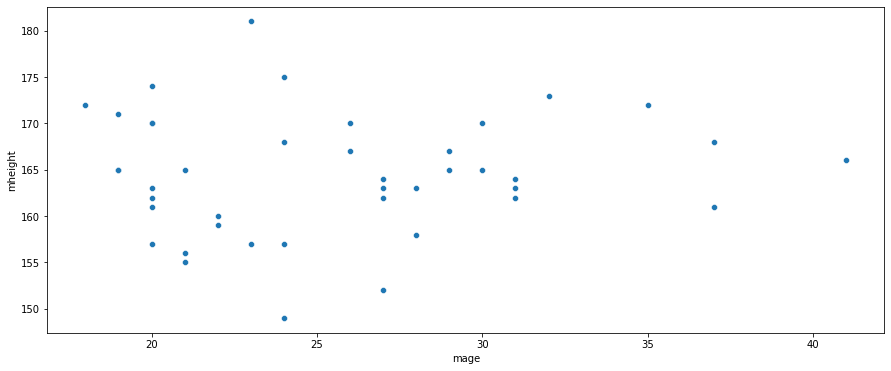

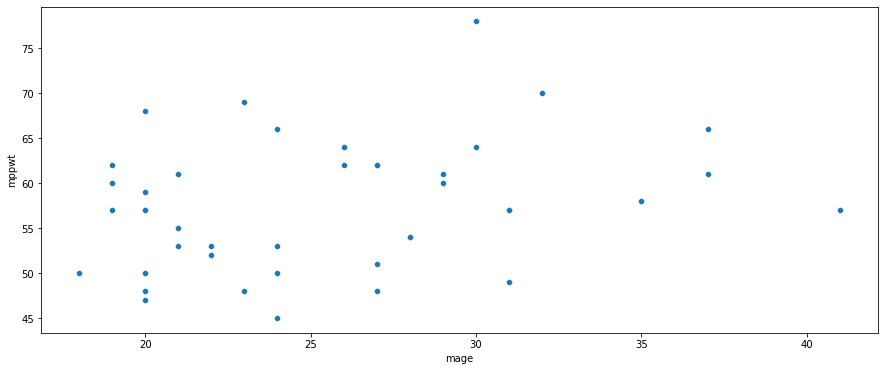

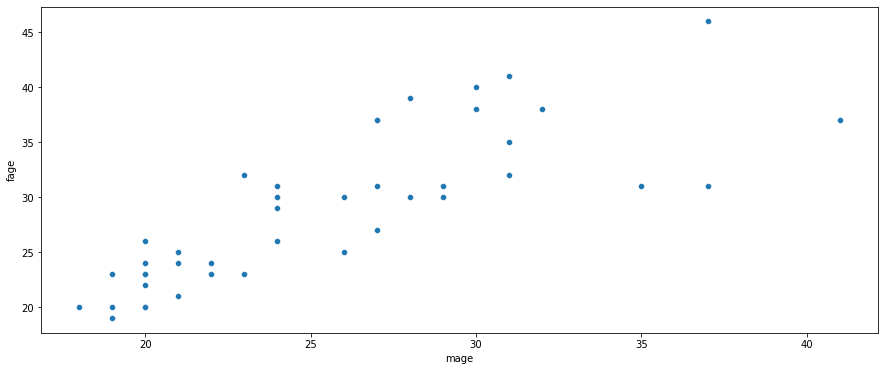

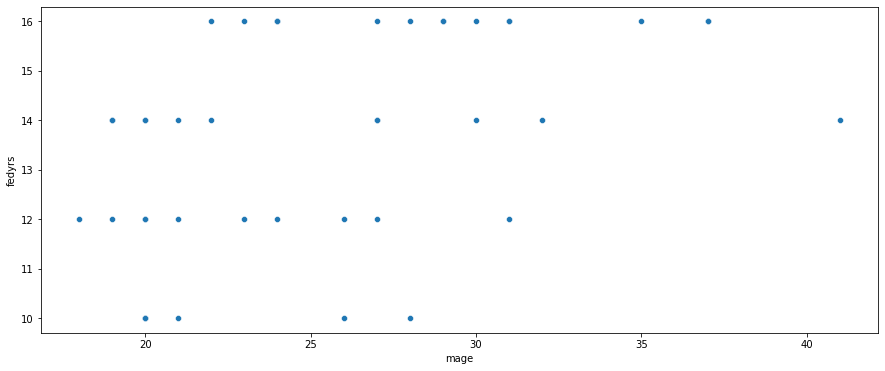

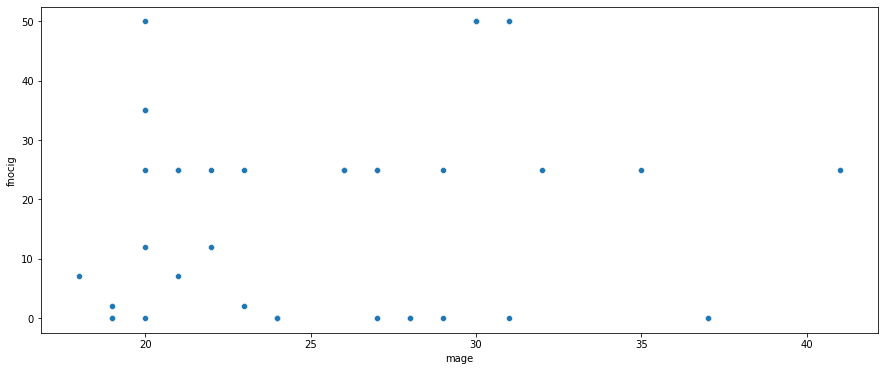

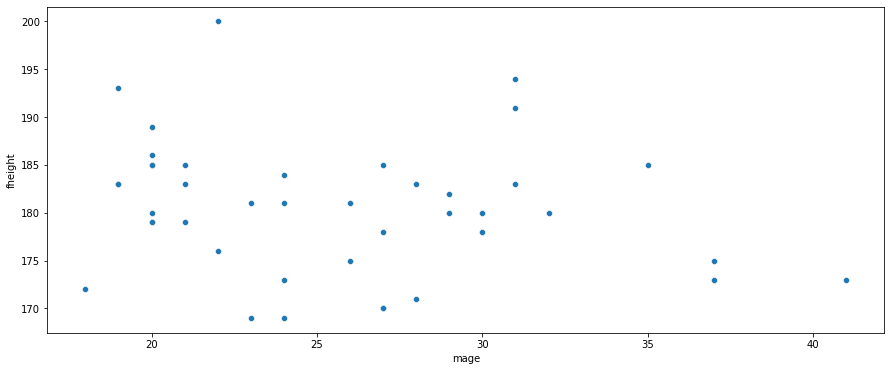

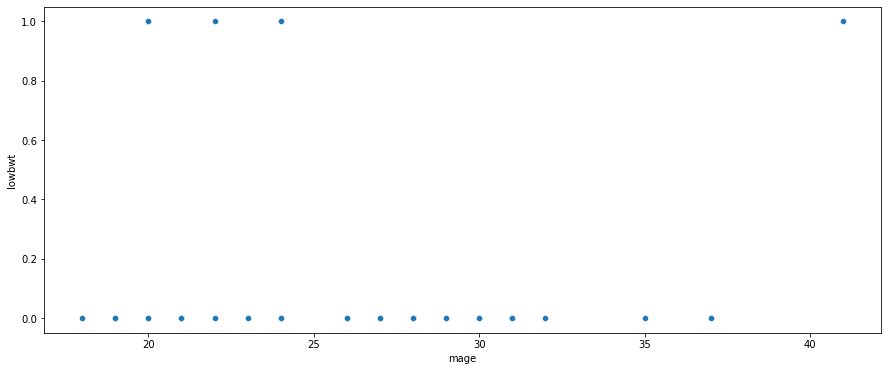

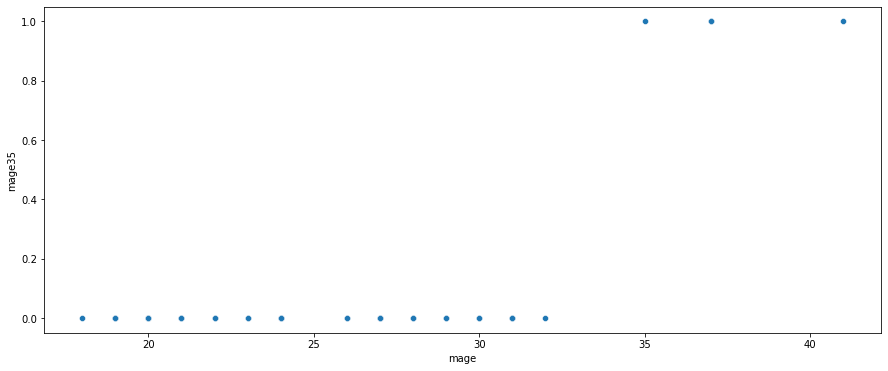

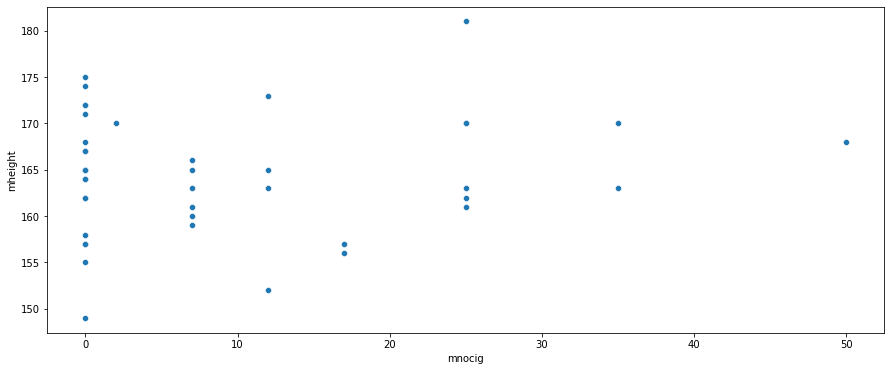

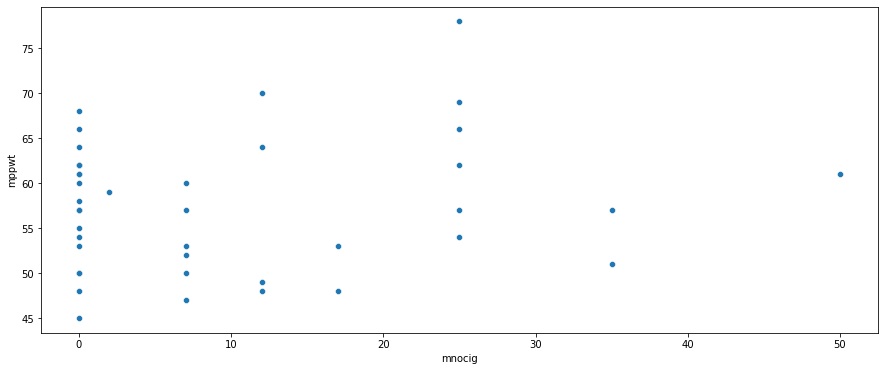

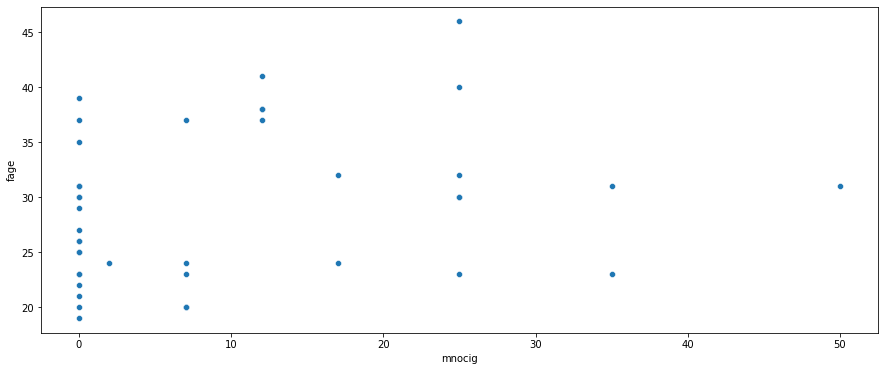

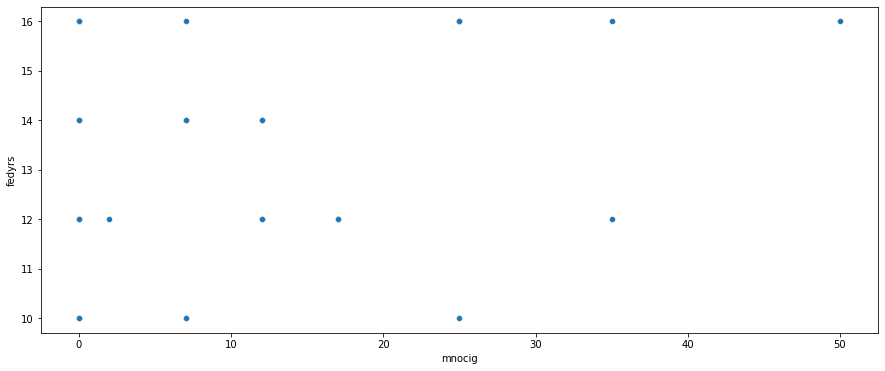

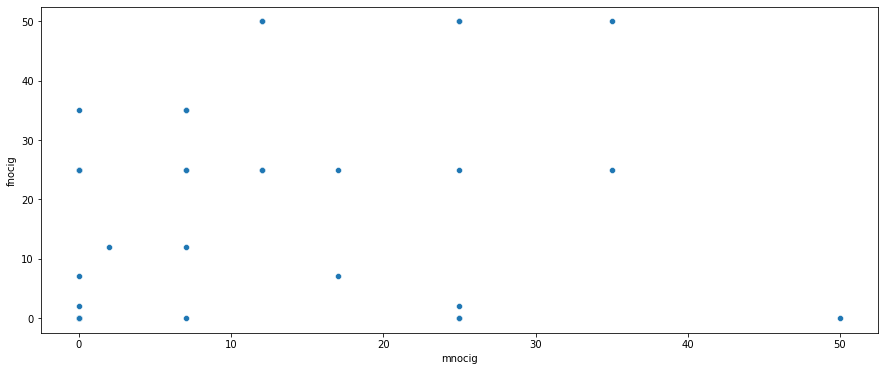

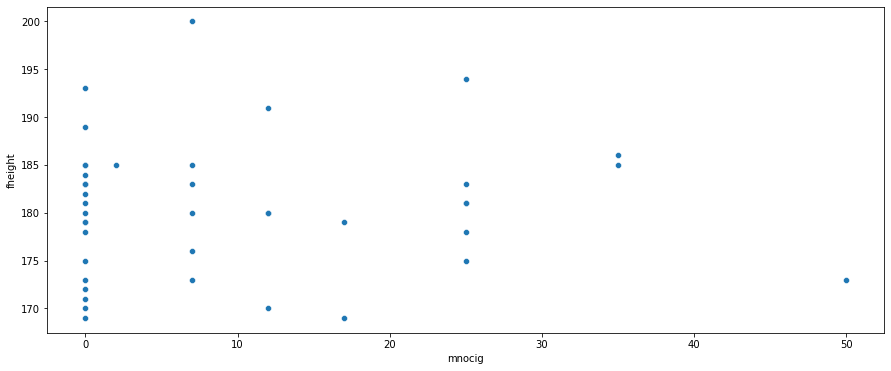

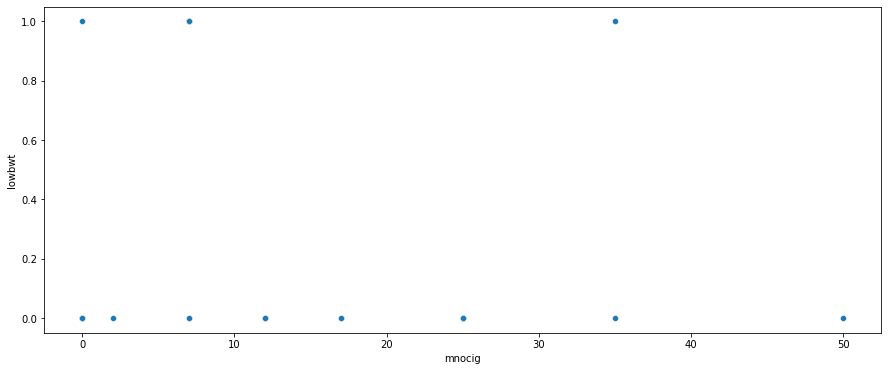

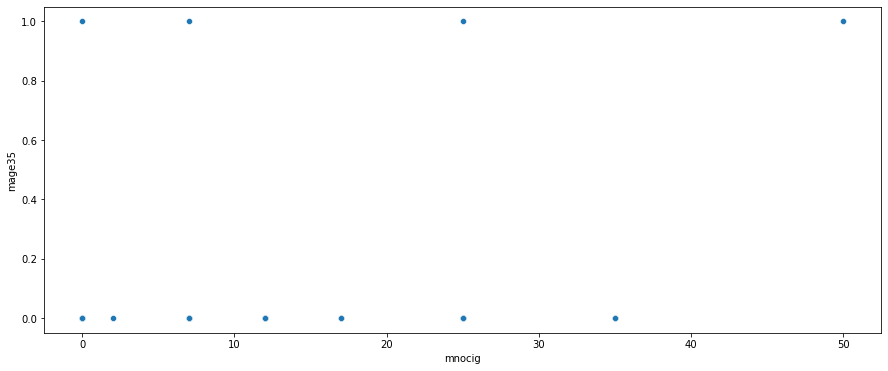

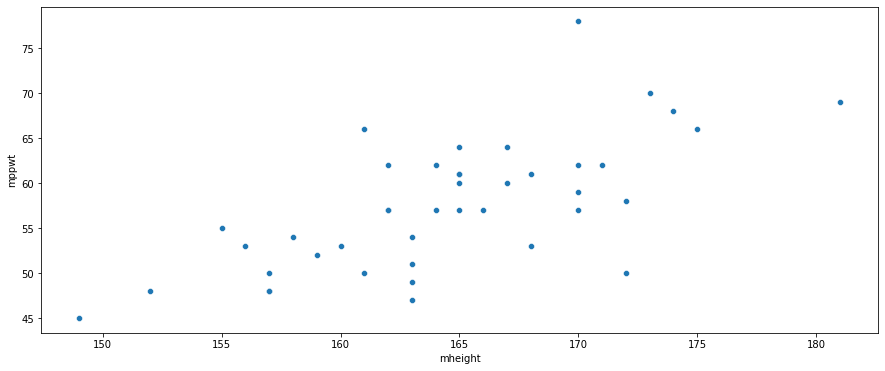

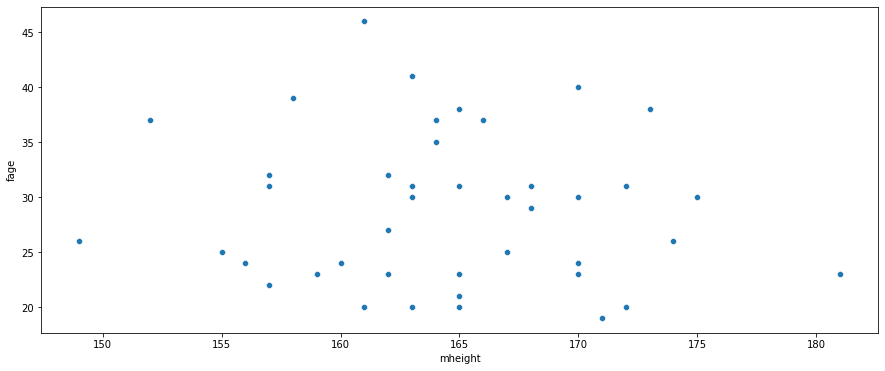

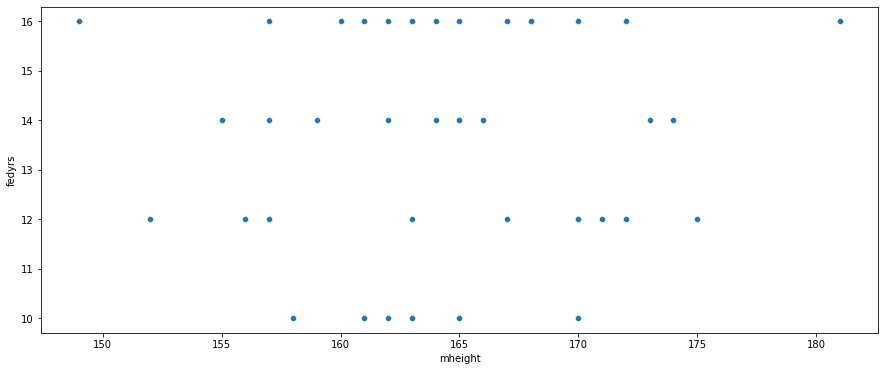

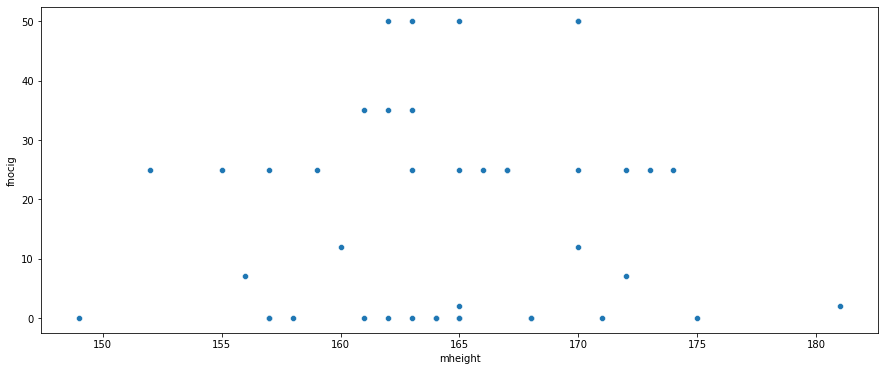

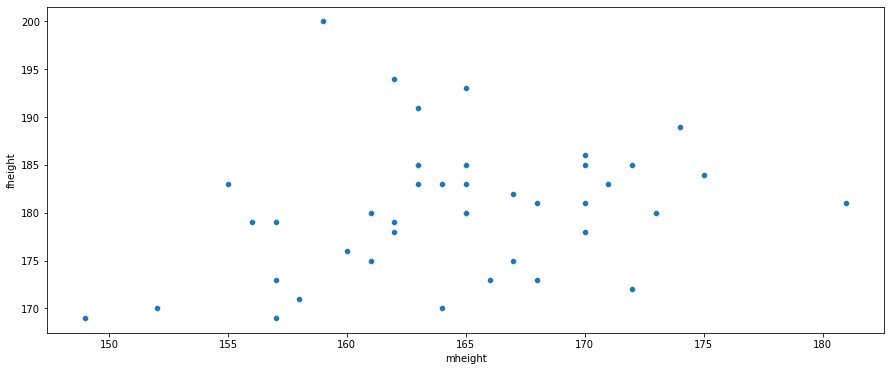

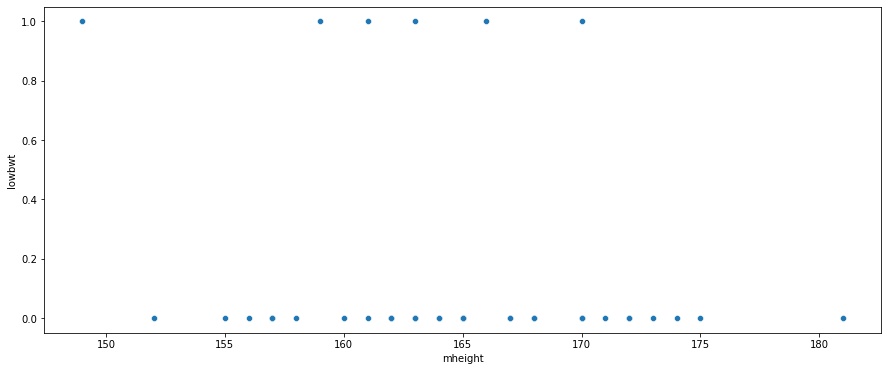

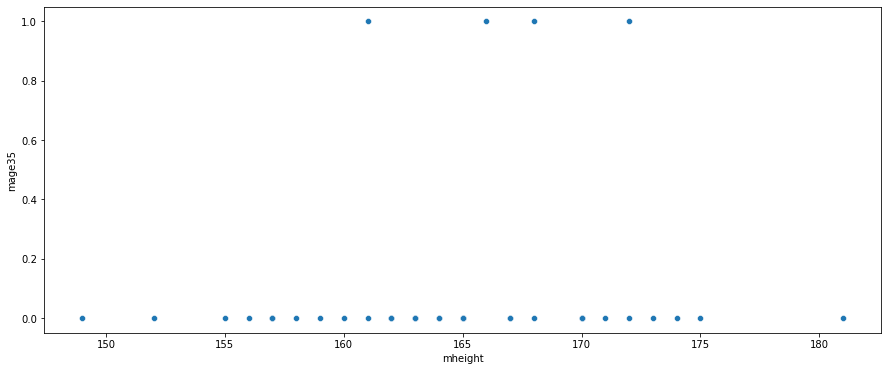

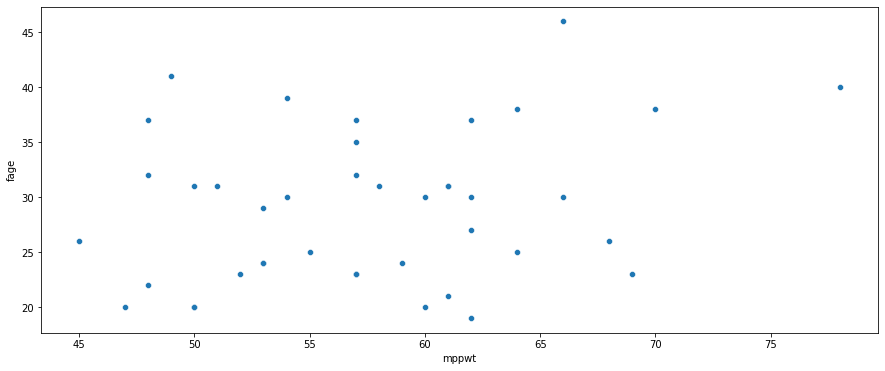

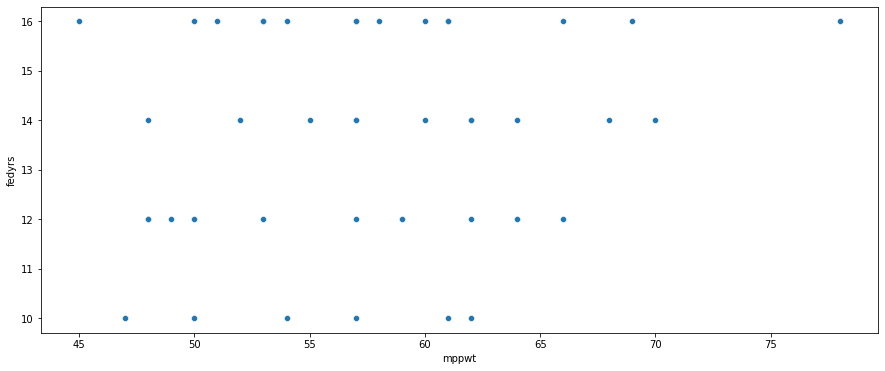

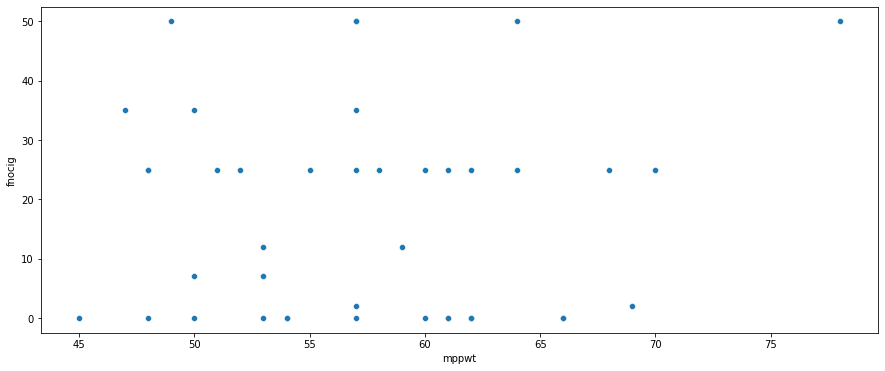

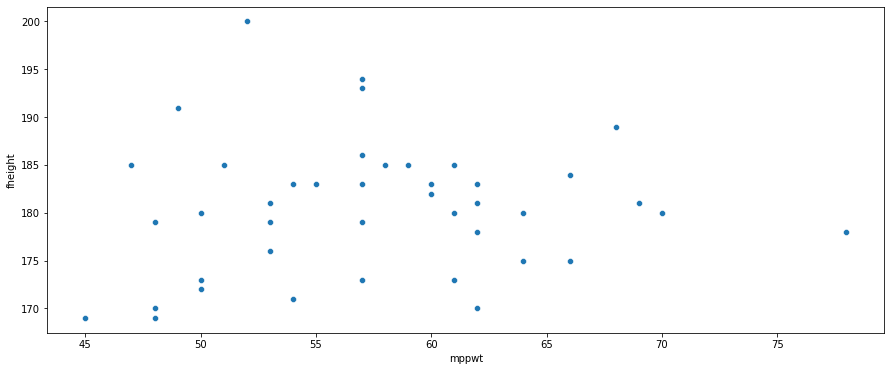

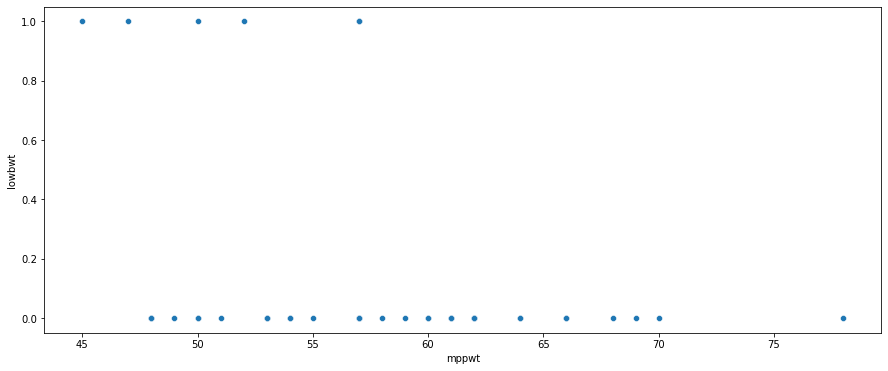

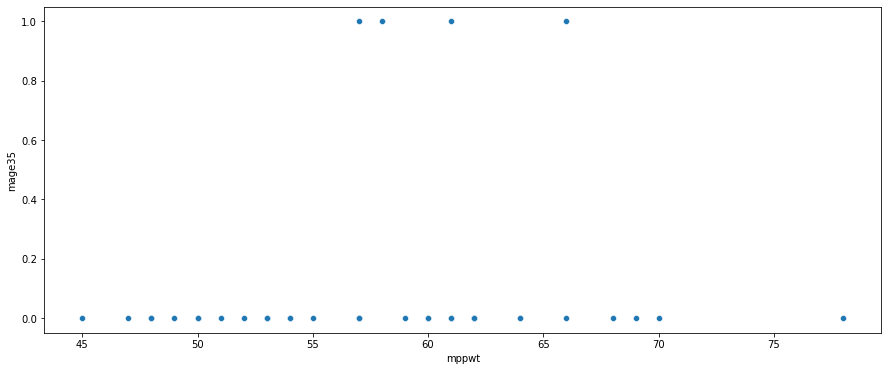

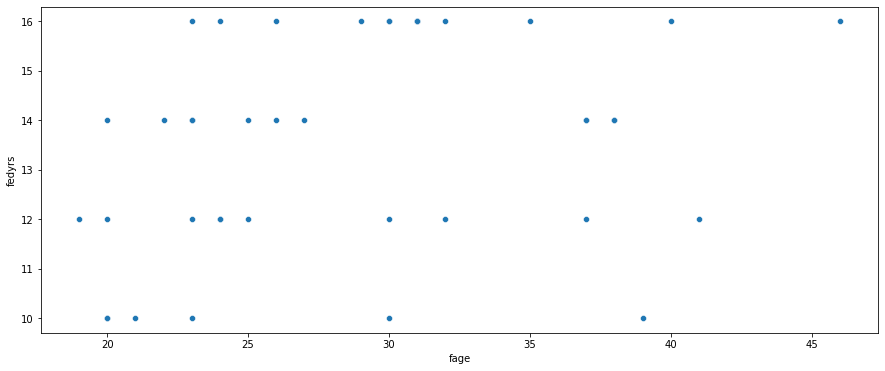

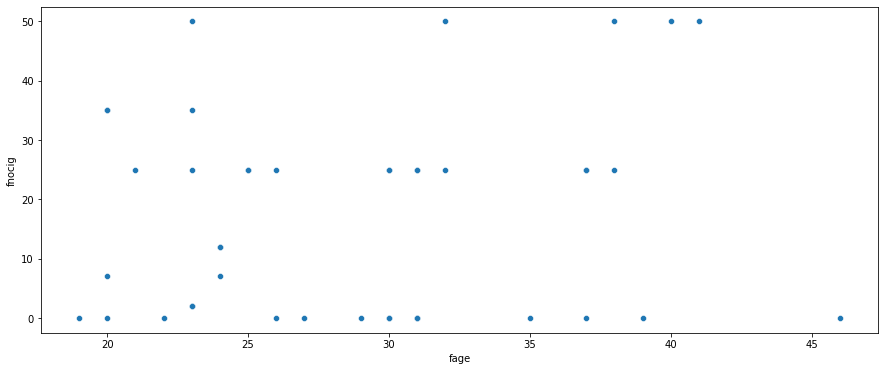

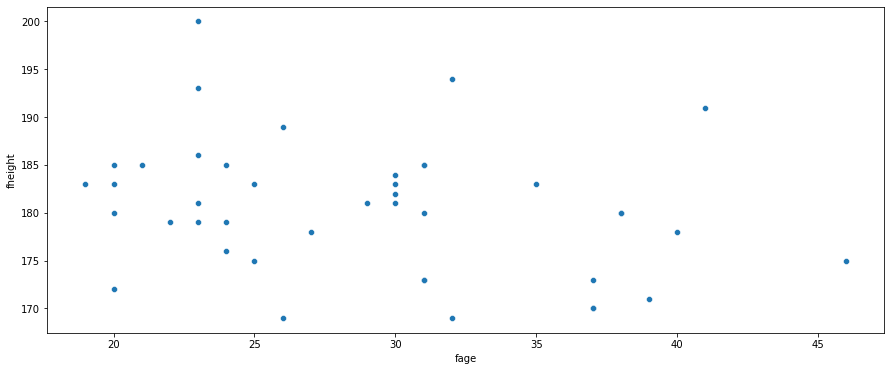

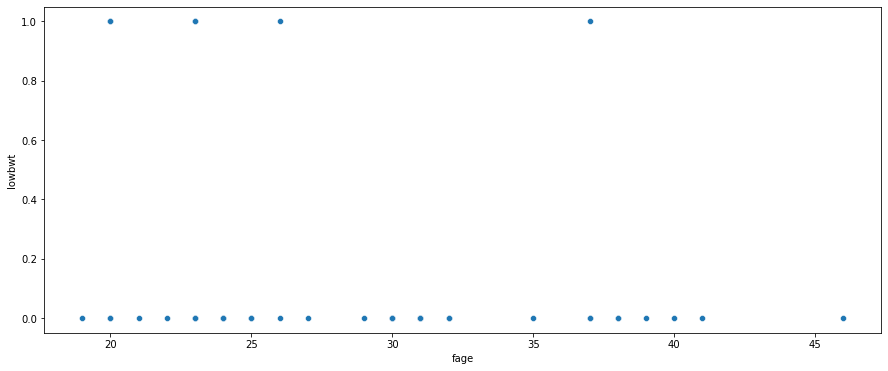

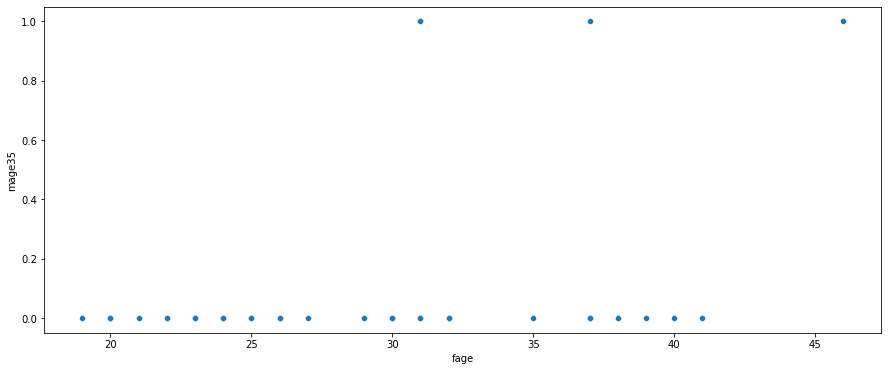

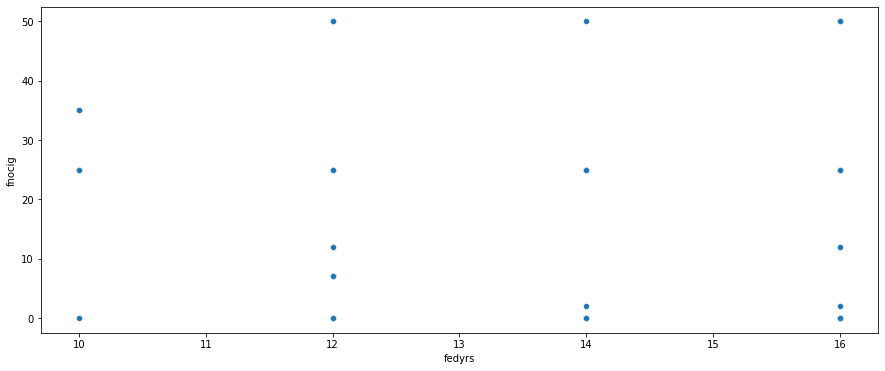

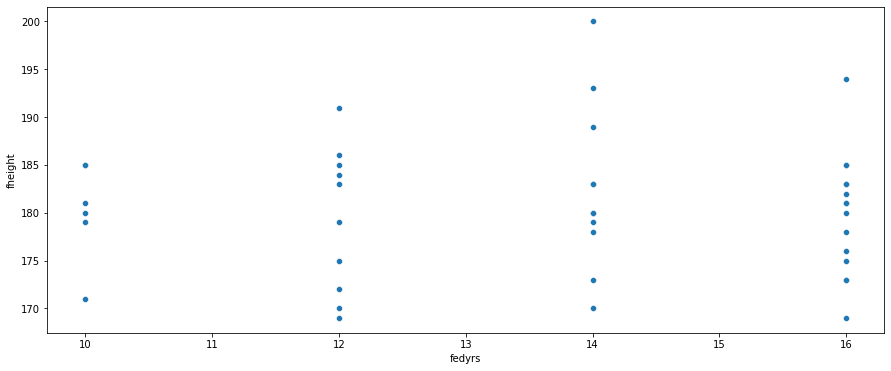

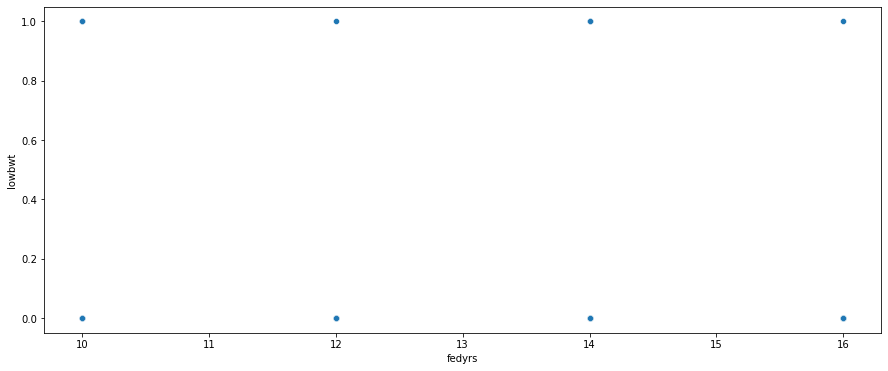

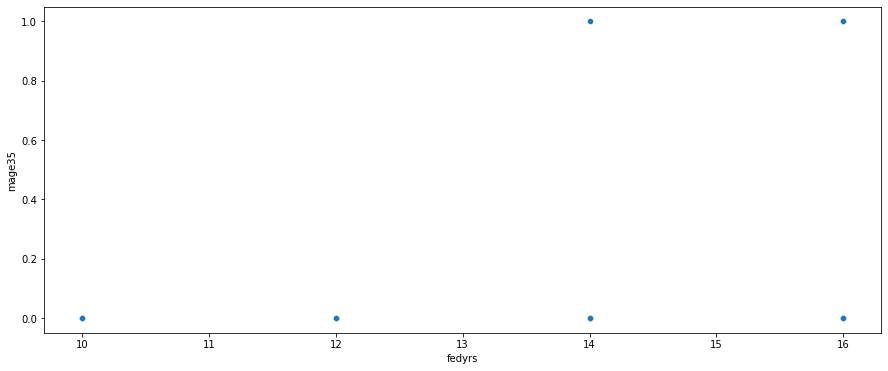

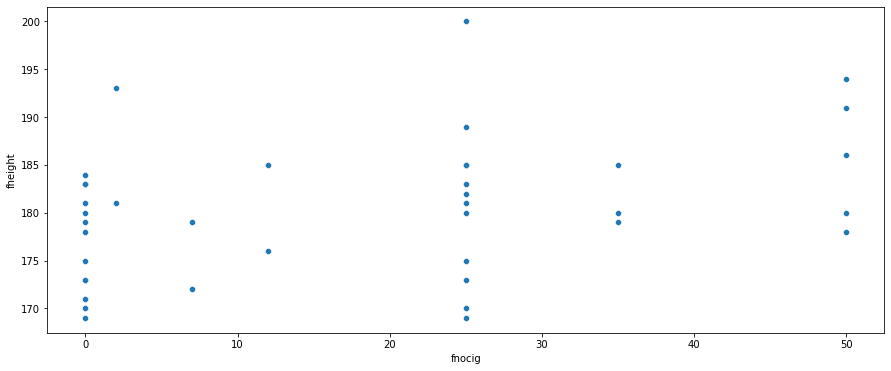

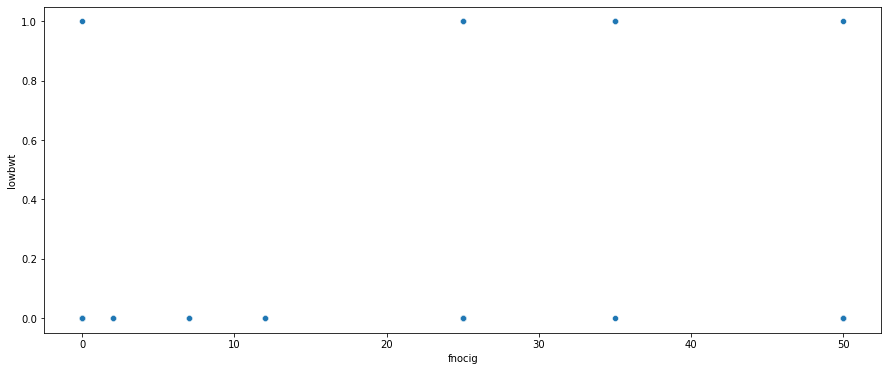

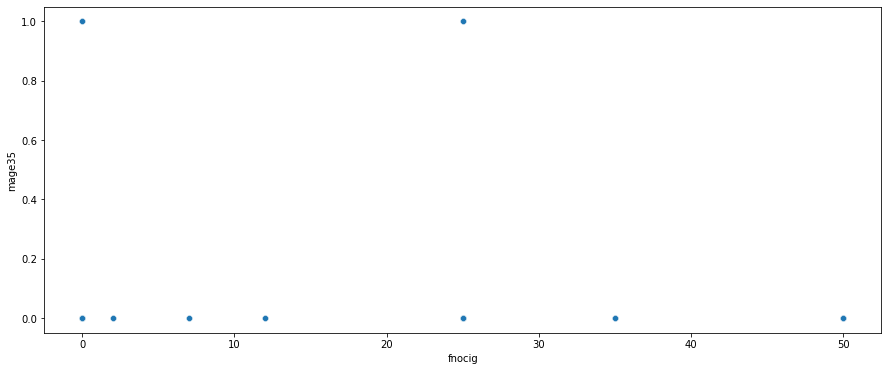

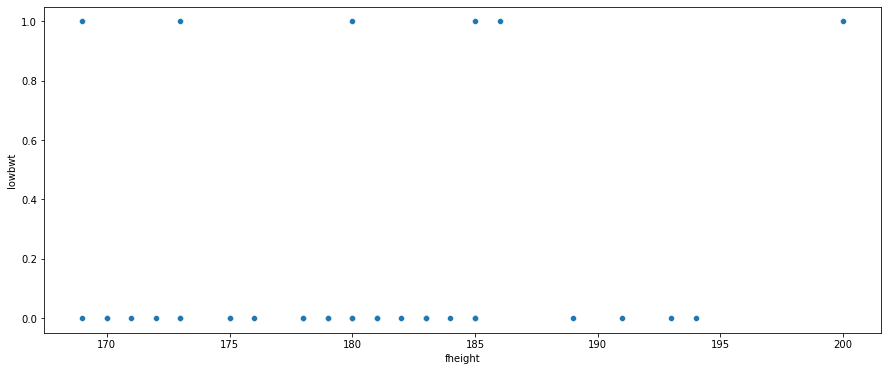

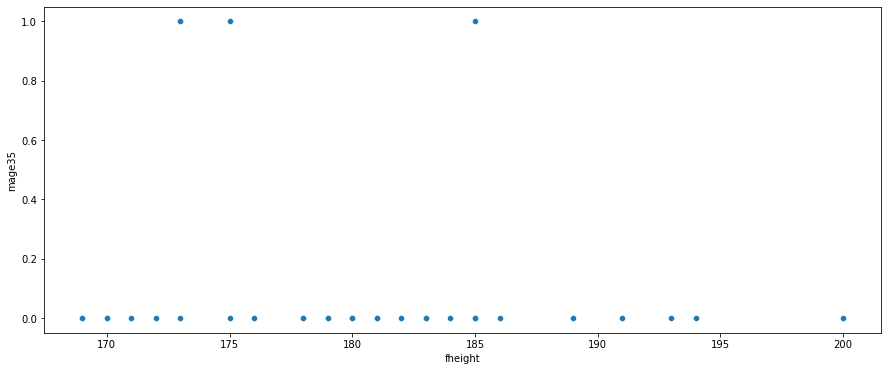

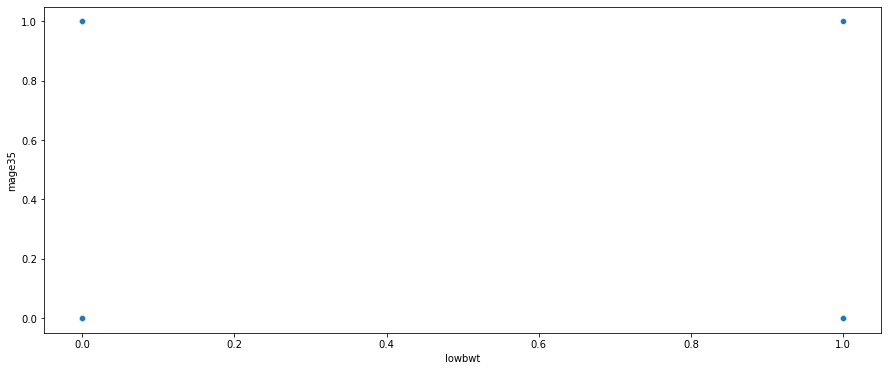

In [62]:
from itertools import combinations

for col_comb in list(combinations(df.columns[1:], 2)):
    fig, ax = plt.subplots(1,1, figsize=(15, 6))
    sns.scatterplot(data=df, x=col_comb[0], y=col_comb[1])


In [65]:
X = df[['Length', 'Headcirc', 'Gestation', 'smoker', 'mage', 'mnocig', 'mheight', 'mppwt', 'fage', 'fedyrs', 'fnocig', 'fheight']]
y = df[['Birthweight']]


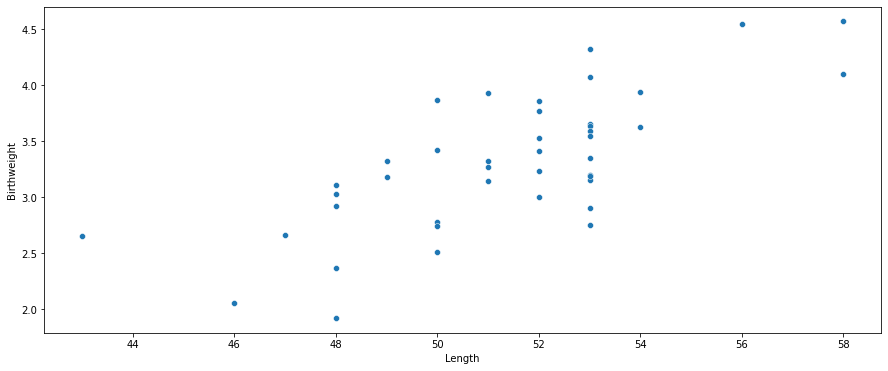

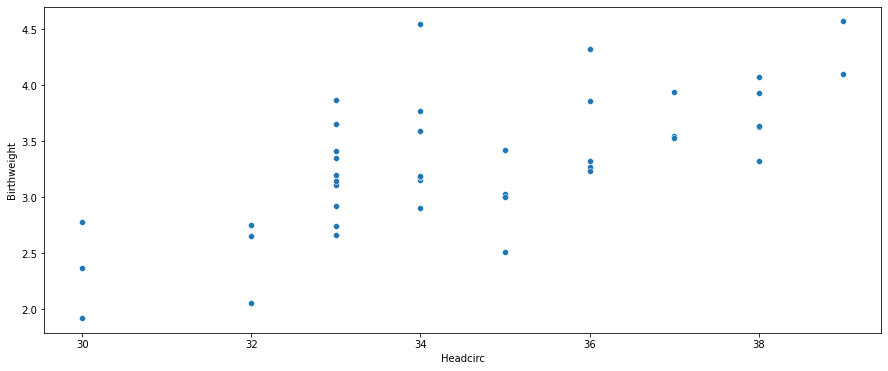

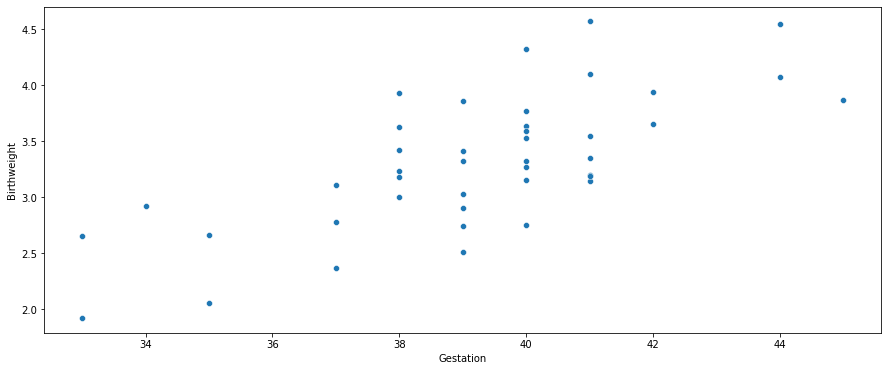

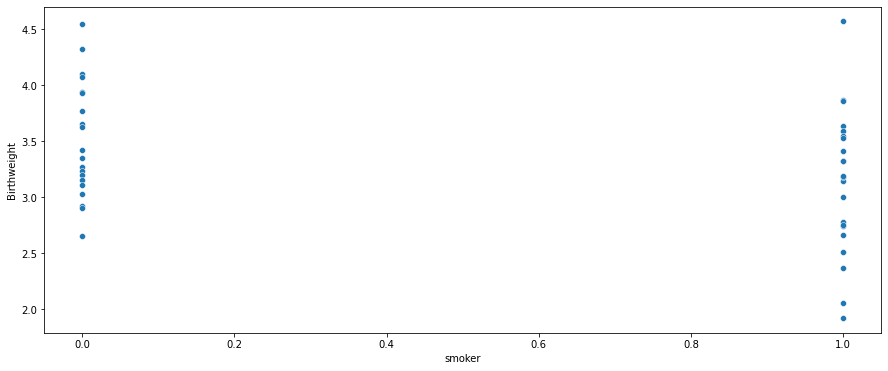

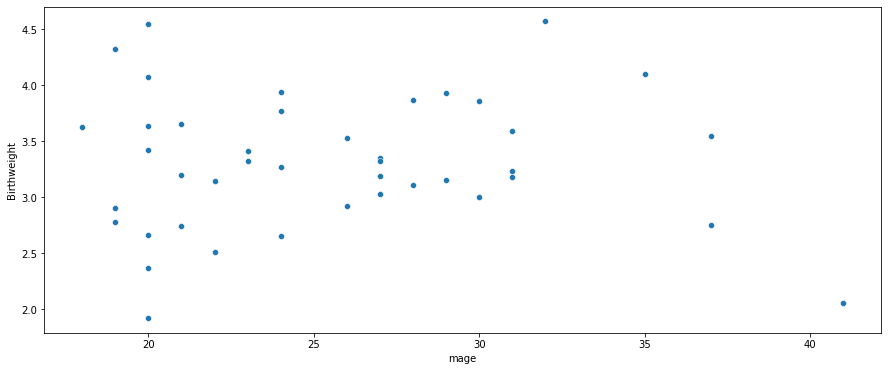

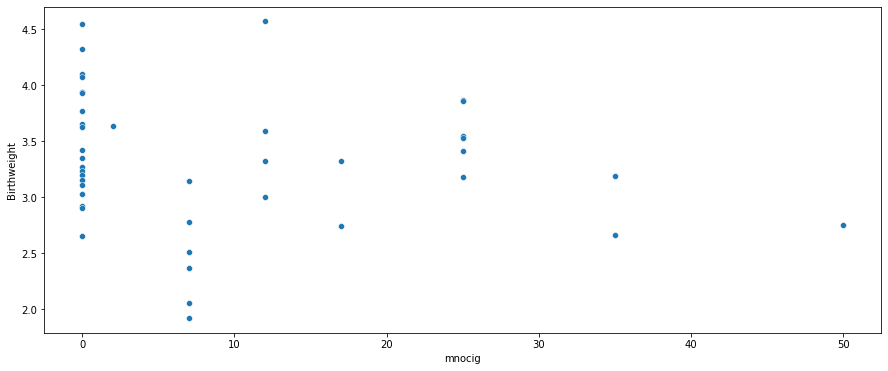

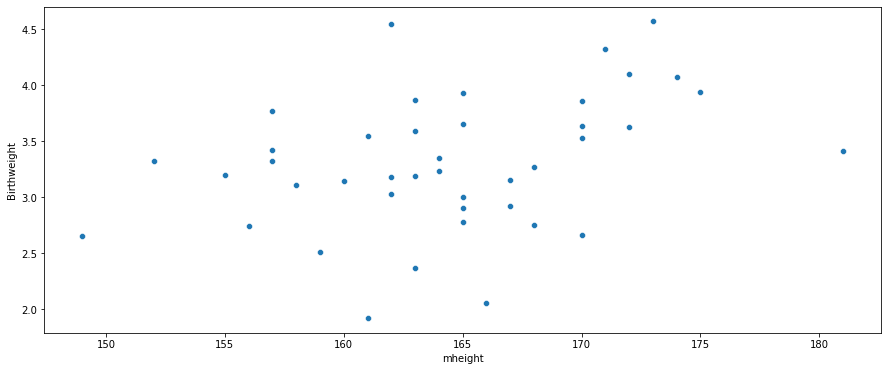

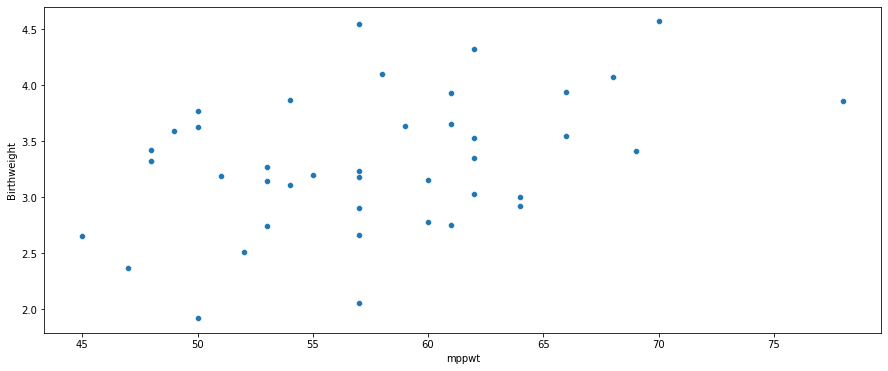

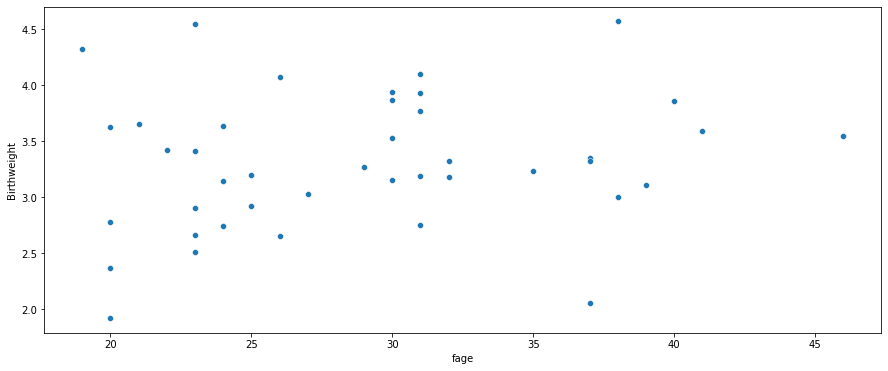

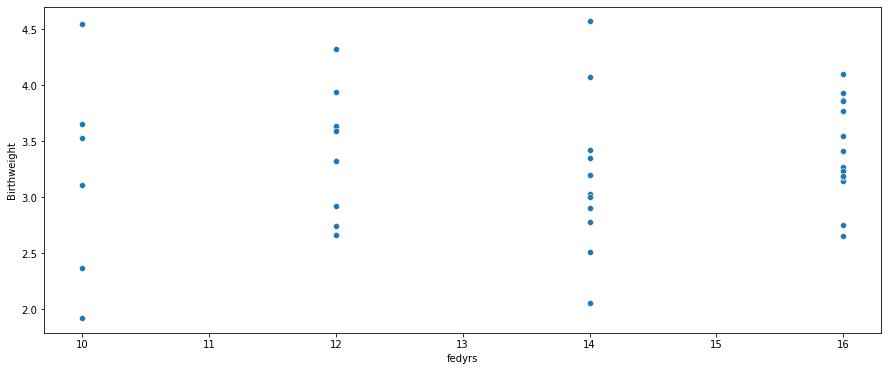

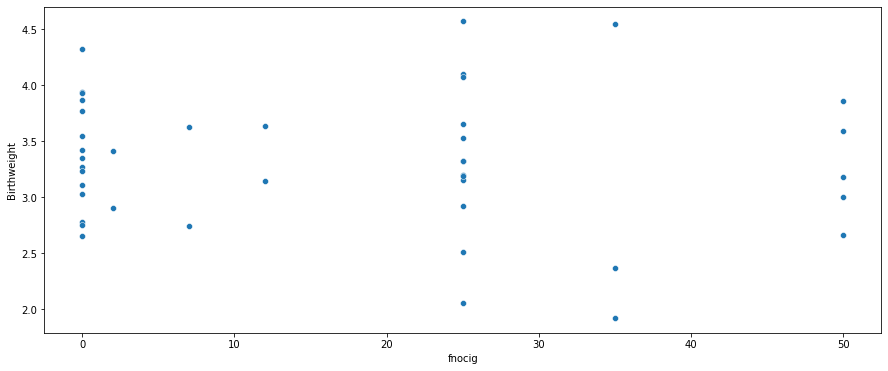

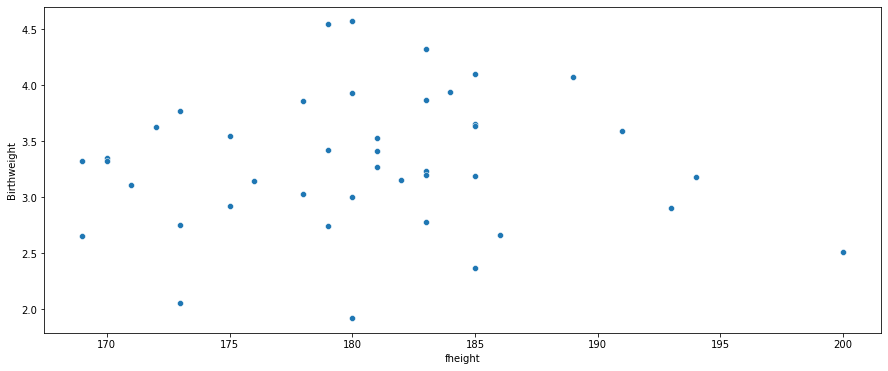

In [66]:
for col in X:
    fig, ax = plt.subplots(1,1, figsize=(15, 6))
    sns.scatterplot(data=df, x=X[col], y=y['Birthweight'])

<AxesSubplot:xlabel='Birthweight', ylabel='Count'>

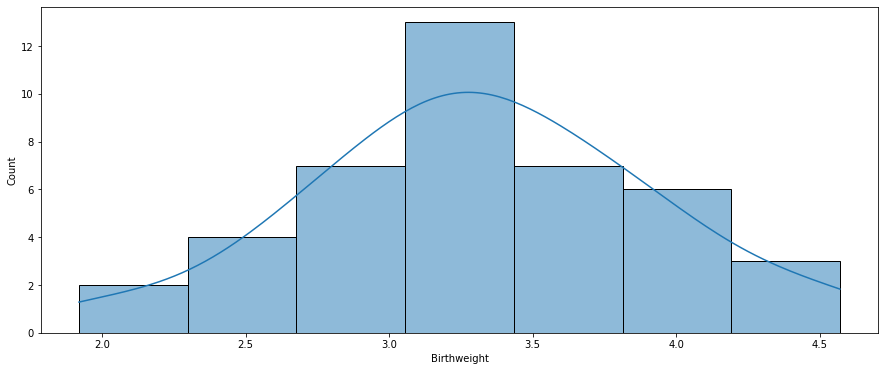

In [19]:
fig, ax = plt.subplots(1,1, figsize=(15, 6))
sns.histplot(data=df, x='Birthweight', kde=True)
#fig, ax = plt.subplots(1,1, figsize=(15, 6))
#df['Birthweight'].plot.box()

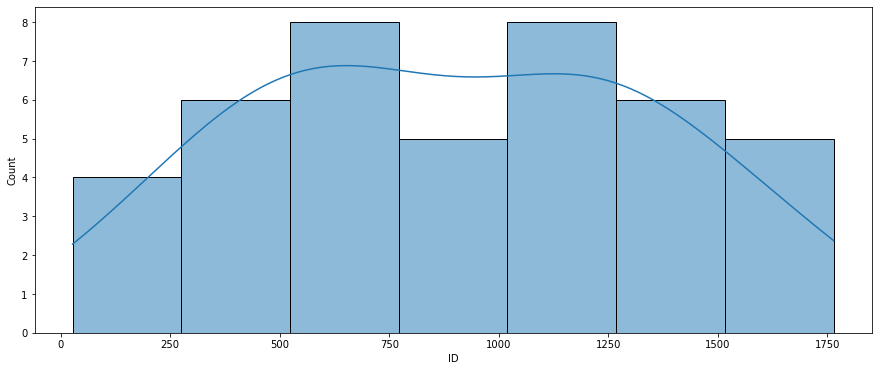

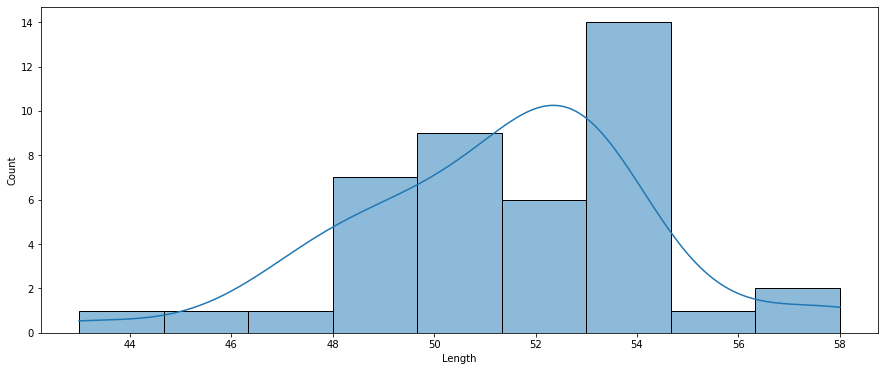

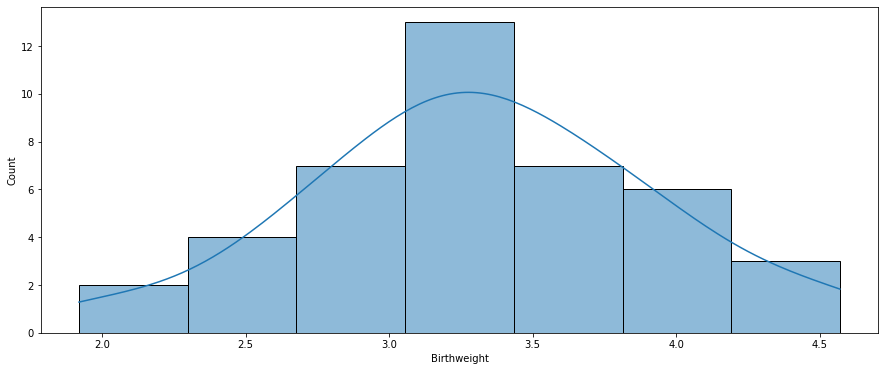

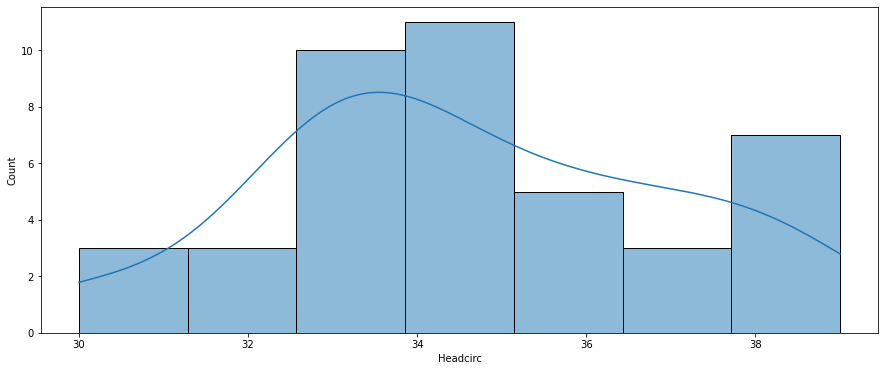

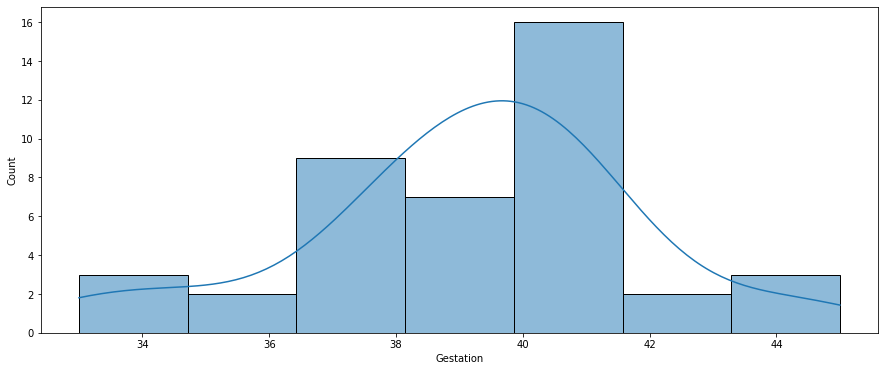

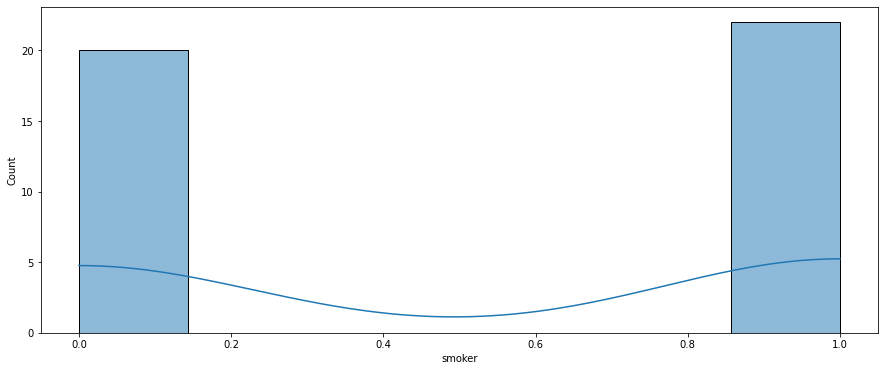

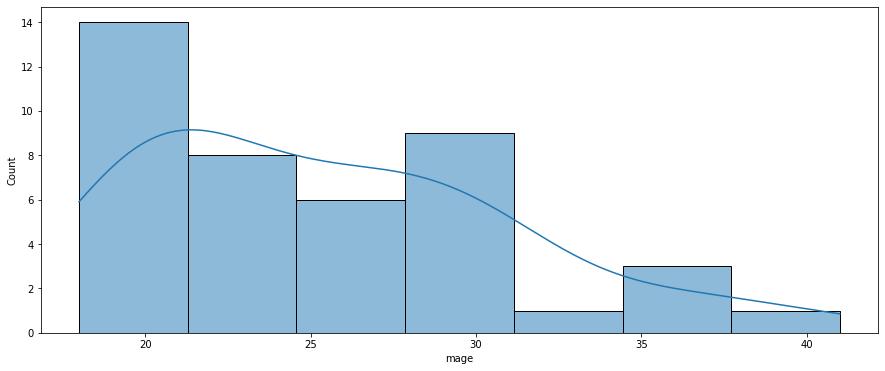

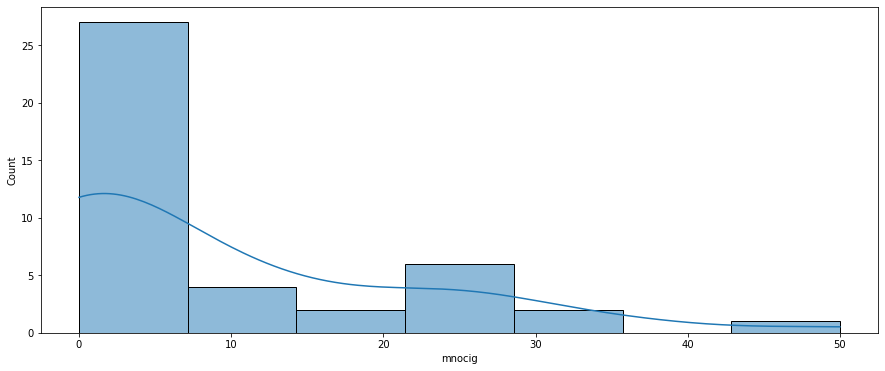

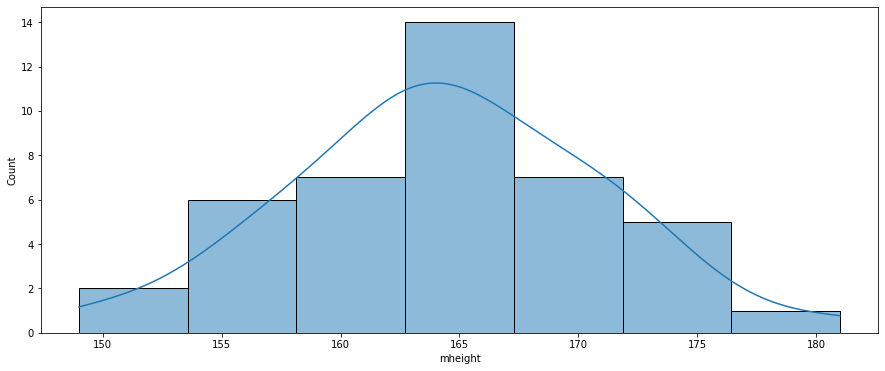

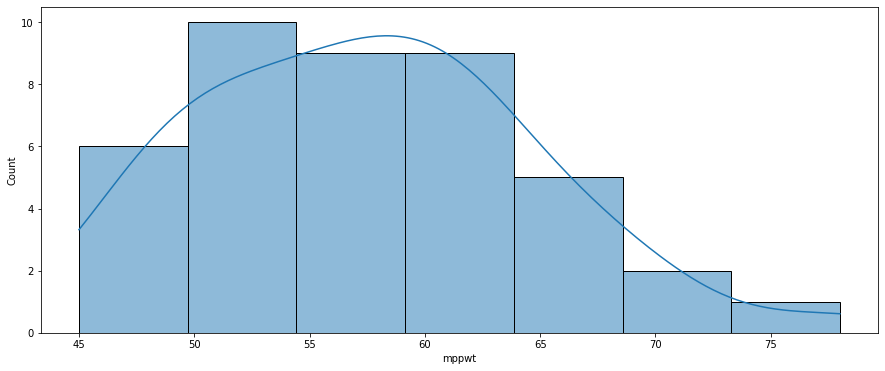

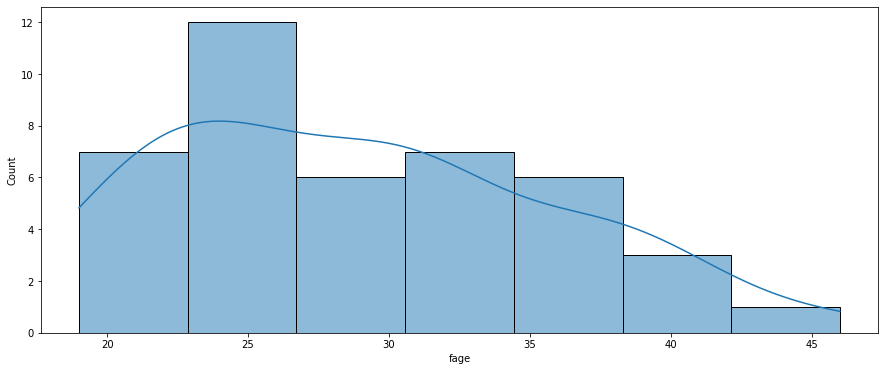

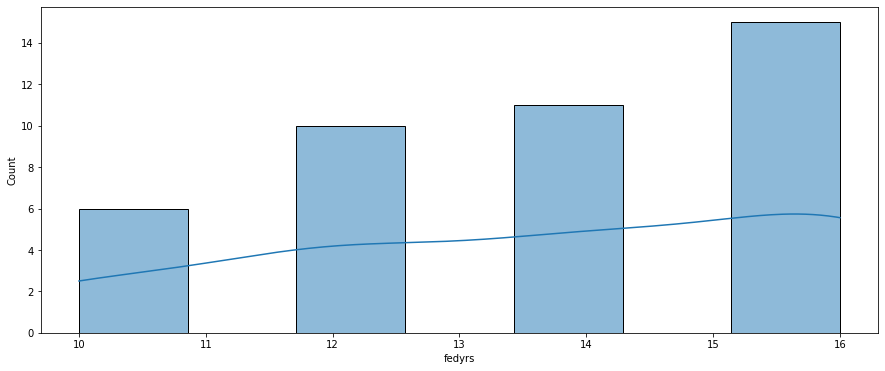

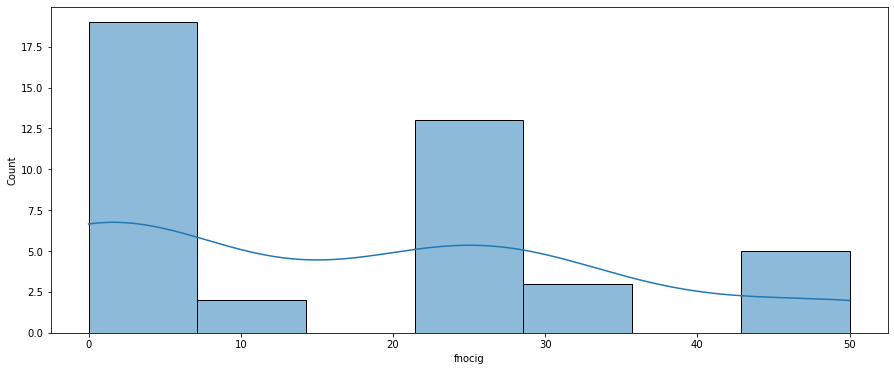

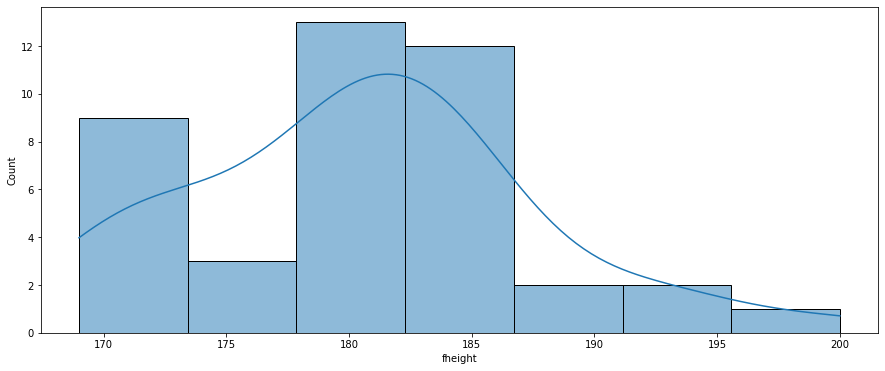

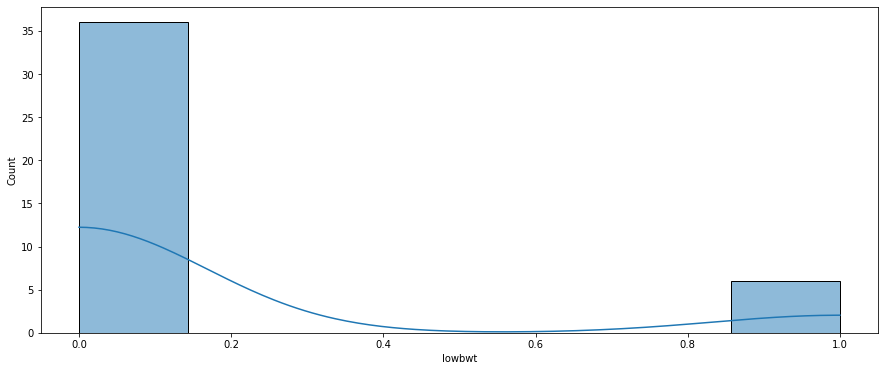

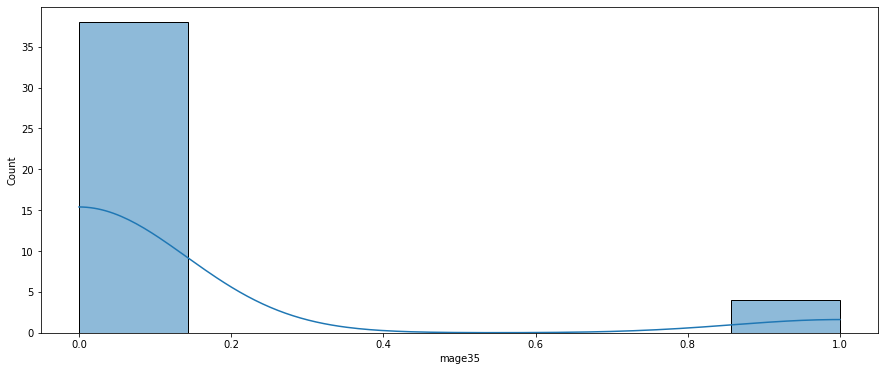

In [67]:
for col in df.columns:
    fig, ax = plt.subplots(1,1, figsize=(15, 6))
    sns.histplot(data=df, x=col, kde=True)

<AxesSubplot:xlabel='mage', ylabel='Count'>

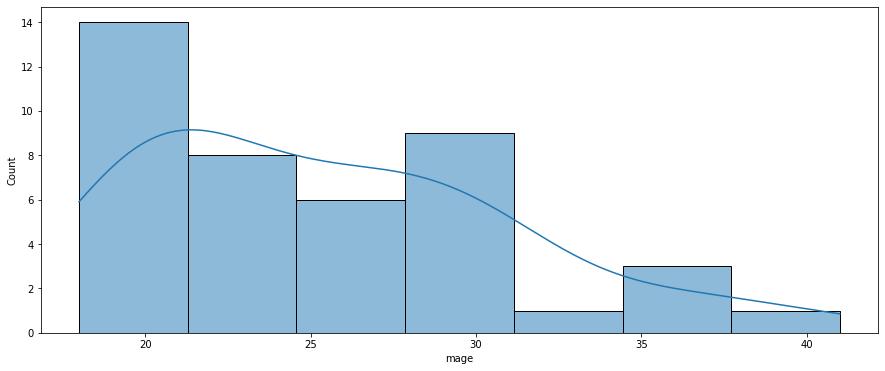

In [69]:
fig, ax = plt.subplots(1,1, figsize=(15, 6))
sns.histplot(data=df, x='mage', kde=True)

<AxesSubplot:xlabel='mage_log', ylabel='Count'>

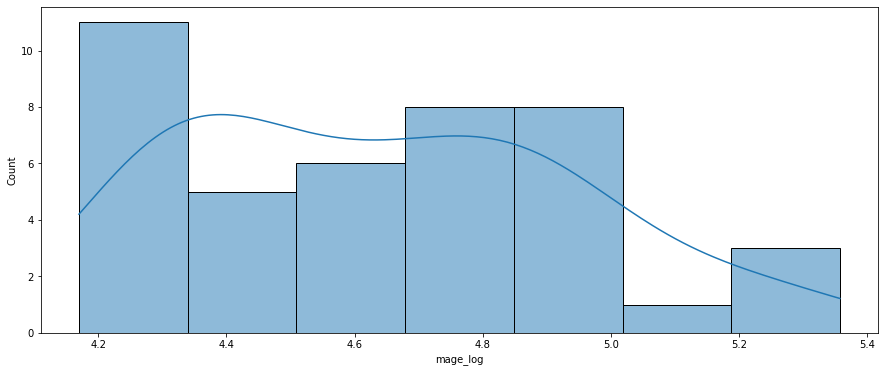

In [70]:
df['mage_log'] = df['mage'].apply(np.log2)
fig, ax = plt.subplots(1,1, figsize=(15, 6))
sns.histplot(data=df, x='mage_log', kde=True)

<AxesSubplot:xlabel='mage', ylabel='Count'>

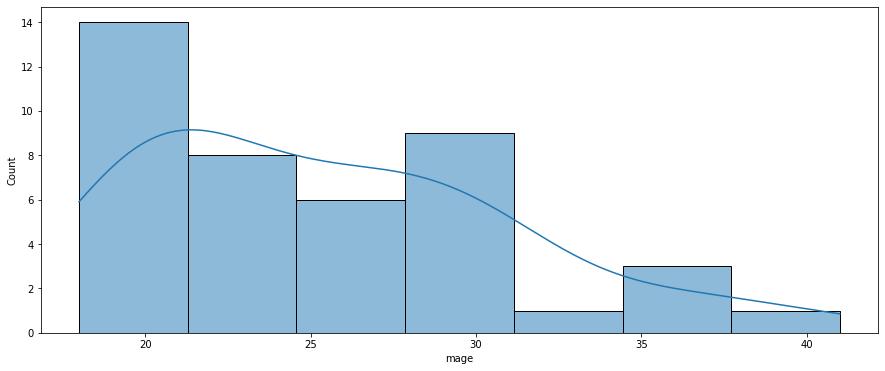

In [71]:
df['mage_sqrt'] = df['mage'].apply(np.sqrt)
fig, ax = plt.subplots(1,1, figsize=(15, 6))
sns.histplot(data=df, x='mage', kde=True)

In [72]:
# Predictors
X = df[['Length', 'Headcirc', 'Gestation', 'smoker', 'mage_sqrt', 'mheight', 'mppwt', 'fage', 'fnocig', 'fheight']]
# Response
y = df[['Birthweight']]

# Split into test and train
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=1)

# Train linear regression model
lm = LinearRegression()
lm.fit(X_train, y_train)

# Make predictions
y_pred = lm.predict(X_test)

# Evaluate
r2 = r2_score(y_test,y_pred)
print("R-Squared: ", r2)


R-Squared:  0.2968982397341793


In [78]:
X = df[['Length', 'Headcirc', 'Gestation', 'smoker', 'mage_sqrt', 'mheight', 'mppwt', 'fnocig', 'fheight']]
y = df[['Birthweight']]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=1)
lm = LinearRegression()
lm.fit(X_train, y_train)
y_pred = lm.predict(X_test)
r2 = r2_score(y_test,y_pred)
print("R-Squared: ", r2)

R-Squared:  0.33348955394574653


### Start experimenting with polynomial regression

In [83]:
polynomial_features= PolynomialFeatures(degree=3)
X_train_poly = polynomial_features.fit_transform(X_train)
X_test_poly = polynomial_features.fit_transform(X_test)
    
plm = LinearRegression()
plm.fit(X_train_poly, y_train)
y_poly_pred = plm.predict(X_test_poly)
r2 = r2_score(y_test,y_poly_pred)
print("R-Squared: ", r2)

regression_model_mse = mean_squared_error(y_poly_pred, y_test)
rmse = np.sqrt(regression_model_mse)
print("RMSE: ", rmse)

R-Squared:  -1.5446387193247175
RMSE:  0.8405309259162338


In [84]:
for i in range(2, 10):
    polynomial_features= PolynomialFeatures(degree=i)
    X_train_poly = polynomial_features.fit_transform(X_train)
    X_test_poly = polynomial_features.fit_transform(X_test)
    print("Polynomial Degree: ", i)
    plm = LinearRegression()
    plm.fit(X_train_poly, y_train)
    y_poly_pred = plm.predict(X_test_poly)
    r2 = r2_score(y_test,y_poly_pred)
    print("R-Squared: ", r2)

    regression_model_mse = mean_squared_error(y_poly_pred, y_test)
    rmse = np.sqrt(regression_model_mse)
    print("RMSE: ", rmse)

Polynomial Degree:  2
R-Squared:  -2.809301511156895
RMSE:  1.0284029319391557
Polynomial Degree:  3
R-Squared:  -1.5446387193247175
RMSE:  0.8405309259162338
Polynomial Degree:  4
R-Squared:  -1.6504647562106745
RMSE:  0.8578308260040829
Polynomial Degree:  5
R-Squared:  -1.8783018519061492
RMSE:  0.8939408843875487
Polynomial Degree:  6
R-Squared:  -2.284829672250938
RMSE:  0.9549861193052184
Polynomial Degree:  7
R-Squared:  -2.913959476291759
RMSE:  1.0424345428745871
Polynomial Degree:  8
R-Squared:  -3.790763325401408
RMSE:  1.1533018528795476
Polynomial Degree:  9
R-Squared:  -5.456757391339693
RMSE:  1.3388991499024054


In [85]:
from sklearn.ensemble import RandomForestRegressor

# instantiate model
model = RandomForestRegressor(random_state=1, max_depth=10)

# fit model
model.fit(X_train, y_train)

<ipython-input-85-039596b5ddbb>:7: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  model.fit(X_train, y_train)


RandomForestRegressor(max_depth=10, random_state=1)

In [86]:
y_pred = model.predict(X_test)

In [87]:
r2 = r2_score(y_test,y_pred)
print("R-Squared: ", r2)

R-Squared:  0.7526251165449763
